# Session 9: Making the Loss Harness Correct and Observable

**What "harness" means here.** The model turns tokens into hidden states, one vector per position. The **loss
harness** is all the code between those hidden states and the single number the optimizer minimises:

- shifting the tokens by one to make the targets;
- masking the positions that must not count (padding, the joins between packed documents);
- the output head that turns each hidden state into one score per vocabulary entry (the logits);
- the cross-entropy, and the average over the positions that count.

The word comes from software testing, where a *test harness* is the code that holds a component and drives it.
Mistakes in these few lines rarely raise an error: the loss still goes down, it just measures the wrong thing.

**The assignment** (ERA V5 course, Session 9: Loss Functions & Output Heads) starts from this four-line harness:

```python
hidden = model(tokens)
logits = output_head(hidden)
loss = cross_entropy(
    logits[:, :-1].reshape(-1, vocab_size),
    tokens[:, 1:].reshape(-1),
)
```

**Part 1.** Make it correct and observable:

1. **Print every tensor shape** and say in one line what each dimension is.
2. **Verify the shift** by printing the actual token strings, inputs beside targets.
3. **Mask padding** and confirm the count of contributing tokens changes.
4. **Pack two documents** into one sequence and mask the boundary. Show the loss before and after, and explain the difference.
5. **Compute perplexity**, and show that an untrained model sits near the vocabulary size.
6. **Compare tied against untied** head parameter counts.
7. **Measure peak memory** for ordinary cross-entropy against a chunked version written by hand. Report both and the ratio.

**Part 2.** Add a second output head that predicts token $t+2$. Report both losses separately and their sum, and
explain how the second head's loss behaves over training compared with the first.

**Part 3.** A target shift in the wrong direction can still produce a beautiful loss curve. Four deliberately
broken harnesses are trained next to the correct one, and the loss each one reports is compared with the honest
loss of the same model.

### Tasks and headline numbers

| Task | Headline number |
|---|---|
| 1. Shapes | the shape table; the logits hold $131\times$ as many numbers as the hidden state |
| 2. Shift | aligned input/target pairs out of all scored pairs |
| 3. Padding | contributing tokens, masked vs counted |
| 4. Packing | loss before and after masking the boundary |
| 5. Perplexity | untrained perplexity compared with the vocabulary size |
| 6. Tied vs untied | 29,938,560 vs 49,255,296 parameters (predicted) |
| 7. Peak memory | ordinary vs chunked cross-entropy, and the ratio |
| Part 2 | head-1 loss, head-2 loss and their sum, for two designs of the second head |
| Part 3 | reported loss vs honest loss for four broken harnesses |

### Setup

- **Model:** a small Llama-style decoder, **29.9M parameters**: 6 layers, width 384, 6 attention heads, RMSNorm,
  RoPE, SwiGLU, input embedding shared with the output head (tied). Code in [`lmharness.py`](lmharness.py).
- **Vocabulary:** the full **GPT-2 vocabulary** plus our own `<pad>` token, rounded up to $V = 50{,}304$. With it
  the output head (19.3M parameters) is bigger than all six layers together (10.6M), so every question about the
  head is visible.
- **Data:** TinyStories, the first 16.4M GPT-2 tokens, read in order, once. Validation is 512 windows of 512 tokens
  from the official validation split.
- **Training:** 16 sequences × 512 tokens per step, 2,000 steps. Every run starts from the same initial weights and
  reads the same tokens in the same order, so two runs differ only in what is being tested.
- **Hardware:** one Colab **L4** GPU, about 30-40 minutes in total.

## Setup

Imports and helpers. Plot colours follow one fixed order: head 1 is always blue, head 2 always orange, the ordinary
loss blue, the chunked loss orange.

In [1]:
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"   # fewer allocator holes in the memory task
!pip -q install tiktoken

import gc, json, math, time, statistics
from contextlib import contextmanager
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

assert torch.cuda.is_available(), "this notebook needs a GPU runtime (L4 recommended)"
props = torch.cuda.get_device_properties(0)
print(f"PyTorch {torch.__version__}, CUDA {torch.version.cuda}")
print(f"GPU: {props.name}, memory {props.total_memory / 2**30:.2f} GiB")
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True

os.makedirs("plots", exist_ok=True)
RESULTS = {}                                         # every headline number; written to results.json as we go

C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({"axes.prop_cycle": plt.cycler(color=C), "lines.linewidth": 2, "axes.grid": True,
                     "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})

def savefig(name):
    "Save the current figure to plots/<name>.png and show it inline."
    plt.savefig(f"plots/{name}.png", dpi=130, bbox_inches="tight")
    plt.show()

def save_results():
    "Write RESULTS to results.json, so a crash late in the notebook loses nothing."
    with open("results.json", "w") as f:
        json.dump(RESULTS, f, default=lambda o: o.tolist() if hasattr(o, "tolist") else str(o))

def smooth(v, w=25):
    "Trailing moving average with window w (shorter at the start). Example: smooth([1, 3, 5], 2) -> [1., 2., 4.]"
    v = np.asarray(v, dtype=float)
    c = np.cumsum(np.insert(v, 0, 0.0))
    i = np.arange(1, len(v) + 1)
    lo = np.maximum(i - w, 0)
    return (c[i] - c[lo]) / (i - lo)

@contextmanager
def no_tf32():
    "Inside this block fp32 matrix products run in true fp32 (TF32 off), for exactness checks."
    old = torch.backends.cuda.matmul.allow_tf32
    torch.backends.cuda.matmul.allow_tf32 = False
    try:
        yield
    finally:
        torch.backends.cuda.matmul.allow_tf32 = old

T_START = time.time()

PyTorch 2.11.0+cu130, CUDA 13.0
GPU: NVIDIA L4, memory 22.03 GiB


## Data: TinyStories with the full GPT-2 vocabulary

Every story gets an `<eot>` (end-of-text, id 50,256) at its end, so stories can be packed back to back. GPT-2 has no
padding token, so `<pad>` (id 50,257) is our own. Reusing `<eot>` as padding would be a quiet bug: masking the padding
would also delete every real "the story ends here" prediction.

The data is downloaded as one parquet file (no streaming) and tokenized in batches.

In [2]:
import tiktoken
import pyarrow.parquet as pq
from huggingface_hub import HfApi, hf_hub_download

enc = tiktoken.get_encoding("gpt2")
EOT_ID, PAD_ID, IGNORE_ID = 50256, 50257, -100    # the same values lmharness defines as EOT, PAD, IGNORE
assert enc.eot_token == EOT_ID and enc.n_vocab == 50257
B, T = 16, 512                                    # sequences per step, tokens per sequence
STEPS = 2000                                      # optimizer steps of every full run
BUG_STEPS = 400                                   # optimizer steps of every Part 3 run
TRAIN_TOKENS = STEPS * B * T                      # 16,384,000: every full run reads exactly these tokens, in order
N_VAL_WINDOWS = 512                               # 512 windows x 512 tokens, used for every validation number

repo = "roneneldan/TinyStories"
files = HfApi().list_repo_files(repo, repo_type="dataset")
train_shards = sorted(f for f in files if f.endswith(".parquet") and "train" in f and "V2" not in f)
val_shards = sorted(f for f in files if f.endswith(".parquet") and "validation" in f and "V2" not in f)

def read_texts(shard):
    "Download one parquet shard whole (no token, no streaming) and return its 'text' column as a list of str."
    return pq.read_table(hf_hub_download(repo, shard, repo_type="dataset"), columns=["text"]).column("text").to_pylist()

def tokenize_docs(texts):
    "Stories -> list of int32 arrays, each followed by <eot>. Example: ['Once upon'] -> [array([7454, 2402, 50256])]"
    return [np.asarray(ids + [EOT_ID], dtype=np.int32) for ids in enc.encode_ordinary_batch(texts, num_threads=8)]

t0 = time.time()
train_docs, n_tok = [], 0
for shard in train_shards:
    texts = read_texts(shard)
    for i in range(0, len(texts), 50_000):
        docs = tokenize_docs(texts[i:i + 50_000])
        train_docs += docs
        n_tok += sum(len(d) for d in docs)
        if n_tok >= TRAIN_TOKENS:
            break
    if n_tok >= TRAIN_TOKENS:
        break
train_np = np.concatenate(train_docs)[:TRAIN_TOKENS]
val_docs = tokenize_docs(read_texts(val_shards[0]))
val_np = np.concatenate(val_docs)
train_tok = torch.from_numpy(train_np).cuda()                                                # (16,384,000,) int32
val_windows = torch.from_numpy(val_np[:N_VAL_WINDOWS * T].reshape(N_VAL_WINDOWS, T)).cuda()  # (512, 512) int32
print(f"download + tokenize: {time.time() - t0:.1f} s")

def tok_str(i):
    """Readable form of one token id.
    Example: tok_str(7454) -> "'Once'";  tok_str(50256) -> '<eot>';  tok_str(-100) -> '(ignored)'"""
    i = int(i)
    if i == EOT_ID:
        return "<eot>"
    if i == PAD_ID:
        return "<pad>"
    if i == IGNORE_ID:
        return "(ignored)"
    if i >= enc.n_vocab:
        return f"<unused {i}>"
    return repr(enc.decode([i]))

lens = np.array([len(d) for d in train_docs])
print(f"training tokens: {TRAIN_TOKENS:,} ({int((train_np == EOT_ID).sum()):,} stories)")
print(f"tokens per story, including its <eot>: mean {lens.mean():.1f}, median {np.median(lens):.0f}; "
      f"so one {T}-token window packs about {T / lens.mean():.1f} stories")
print(f"validation: {N_VAL_WINDOWS} windows x {T} = {N_VAL_WINDOWS * T:,} tokens")
print("first 14 training tokens as strings:", " ".join(tok_str(i) for i in train_np[:14]))
RESULTS["data"] = {"train_tokens": TRAIN_TOKENS, "mean_story_tokens": float(lens.mean())}

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


data/train-00000-of-00004-2d5a1467fff108(…): reconstructing file:   0%|          |  0.00B /  249MB            

data/train-00000-of-00004-2d5a1467fff108(…): downloading bytes:           |  0.00B            

data/validation-00000-of-00001-869c898b5(…): reconstructing file:   0%|          |  0.00B / 9.99MB            

data/validation-00000-of-00001-869c898b5(…): downloading bytes:           |  0.00B            

download + tokenize: 17.8 s
training tokens: 16,384,000 (73,941 stories)
tokens per story, including its <eot>: mean 219.5, median 190; so one 512-token window packs about 2.3 stories
validation: 512 windows x 512 = 262,144 tokens
first 14 training tokens as strings: 'One' ' day' ',' ' a' ' little' ' girl' ' named' ' Lily' ' found' ' a' ' needle' ' in' ' her' ' room'


## The model and the harness code

Each of the 6 layers does two things and adds the result back to its input: attention (each token gathers
information from the tokens before it), then a feed-forward network (each token processes what it gathered). The
output of the last layer, after a final normalisation, is the **hidden state**: 384 numbers per position.

The code is split the way the assignment's harness is written:

| Assignment line | Our call | Shape |
|---|---|---|
| `hidden = model(tokens)` | `hidden = model(tokens, doc=doc_ids(tokens))` | (16, 512) → (16, 512, 384) |
| `logits = output_head(hidden)` | `logits = model.head(hidden)` | → (16, 512, 50,304) |
| `tokens[:, 1:]` | `make_targets(tokens, 1)`: the same shift, with `-100` where a pair must not count | (16, 511) |
| (Part 2) | `logits2 = model.head2(hidden, tokens)` against `make_targets(tokens, 2)` | (16, 510, 50,304) |

`doc=doc_ids(tokens)` tells attention where each packed story starts, so a token never looks into the previous
story.

**Parameter count:**

| Part | Calculation | Parameters |
|---|---|---:|
| Embedding (also the output head, when tied) | 50,304 × 384 | 19,316,736 |
| One layer (attention 589,824 + feed-forward 1,179,648 + 2 norms 768) | | 1,770,240 |
| 6 layers + final norm | | 10,621,824 |
| **Tied model** | | **29,938,560** |
| **Untied model** (its own output head) | + 50,304 × 384 | **49,255,296** |

Colab cannot see local files, so the next cell writes the module onto the runtime.

In [3]:
%%writefile lmharness.py
"""Llama-style decoder LM and an observable next-token loss harness (ERA V5, Session 9).

Architecture (pre-norm Llama block, the same family as Assignments 10-14):

    token ids (B, T)
      -> Embedding E (V, D)                                             x (B, T, D), fp32 residual stream
      -> L blocks:  x = x + Attn(RMSNorm(x))          causal, optional document mask, RoPE
                    x = x + SwiGLU(RMSNorm(x))
      -> final RMSNorm                                                  hidden (B, T, D)
      -> head 1:  logits  = hidden @ W1^T,  W1 = E (tied) or its own (V, D) matrix      predicts token t+1
      -> head 2 (optional), predicts token t+2 from position t:
            "dense":      logits2 = h_t @ W2^T with its own (V, D) matrix                (reads h_t only)
            "cheap":      logits2 = RMSNorm(h_t + SwiGLU2(RMSNorm(h_t))) @ W1^T          (reads h_t only)
            "sequential": u_t = Merge([RMSNorm(h_t); RMSNorm(E[x_{t+1}])])  (2D -> D), one causal Block over u,
                          logits2 = RMSNorm(u_t) @ W1^T                  (DeepSeek-V3 style: also reads the true
                                                                          token t+1 in training, head 1's guess at
                                                                          inference)

The loss harness (everything between the hidden state and the scalar loss):

    targets_k[t] = tokens[t + k]   if positions t and t + k are in the same document and neither is padding
                 = IGNORE (-100)   otherwise
    loss_k       = sum over valid t of  -log softmax(logits_k[t])[targets_k[t]]   /   number of valid t

ChunkedCrossEntropy computes loss_1 from (hidden, W1) without ever holding the (N, V) logits: it walks over the rows
in chunks, keeps one log-normaliser per row, and recomputes each chunk's logits in the backward pass.

Notation in docstrings and shape comments:
    B sequences per batch   T tokens per sequence   D d_model   H heads   hd = D / H   F FFN width
    V vocabulary size       L layers                N rows given to the loss (B * (T - 1) for head 1)
"""
import gc
import math
import time
from dataclasses import dataclass

import torch
import torch.nn as nn
import torch.nn.functional as F

EOT = 50256          # GPT-2 <|endoftext|>: closes every document
PAD = 50257          # our own padding id (GPT-2 has none); never appears in packed training data
IGNORE = -100        # target value that F.cross_entropy(ignore_index=IGNORE) skips


@dataclass
class Config:
    vocab_size: int = 50304        # V: GPT-2's 50,257 ids + PAD, rounded up to a multiple of 64 (46 rows never used)
    n_layer: int = 6               # L
    n_head: int = 6                # H   (hd = 384 / 6 = 64)
    d_model: int = 384             # D
    d_ff: int = 1024               # F = 8/3 * D, the SwiGLU width with the same budget as a 4x two-matrix FFN
    max_seq: int = 512             # T the RoPE tables are built for
    rope_base: float = 10000.0
    tie: bool = True               # head 1 reuses the embedding matrix
    head2: str = "none"            # "none" | "dense" | "cheap" | "sequential"
    init_std: float = 0.02         # std of every weight matrix (residual output projections get / sqrt(2L))
    head_init_std: float = 0.02    # std of an untied head 1 and of a dense head 2
    seed: int = 0                  # init seed; embedding and trunk come first, so every config shares them


# ----------------------------------------------------------------------------------------- targets
def doc_ids(tokens, eot=EOT):
    """Document index of every position; an <eot> belongs to the document it closes.

    Example: doc_ids(torch.tensor([[5, 6, EOT, 7, 8]])) -> tensor([[0, 0, 0, 1, 1]])
    """
    is_eot = (tokens == eot).long()                                         # (B, T)
    return torch.cumsum(is_eot, dim=1) - is_eot                             # number of <eot> strictly before t


def make_targets(tokens, k=1, *, mask_pad=True, mask_boundary=True, eot=EOT, pad=PAD):
    """Targets for logits[:, :-k]: target[t] = tokens[t + k], or IGNORE where that pair must not count. (B, T-k).

    mask_boundary: ignore the pair if t and t + k sit in different documents (the next document is unrelated).
    mask_pad:      ignore the pair if the input or the target is padding.
    Example (k=1): tokens [[5, 6, EOT, 7, 8, PAD]] -> [[6, EOT, IGNORE, 8, IGNORE]]
        6 after 5: kept;  EOT after 6: kept (ending a document is a real prediction);
        7 after EOT: first token of a new document -> IGNORE;  8 after 7: kept;  PAD after 8 -> IGNORE.
    Example (k=2): tokens [[5, 6, EOT, 7, 8, 9]] -> [[EOT, IGNORE, IGNORE, 9]]
        (6 -> 7 and EOT -> 8 both jump into the next document; 7 -> 9 stays inside it)
    """
    tgt = tokens[:, k:].clone()                                             # (B, T-k)
    if mask_boundary:
        d = doc_ids(tokens, eot)
        tgt[d[:, k:] != d[:, :-k]] = IGNORE
    if mask_pad:
        tgt[(tokens[:, k:] == pad) | (tokens[:, :-k] == pad)] = IGNORE
    return tgt


# ----------------------------------------------------------------------------------------- layers
class RMSNorm(nn.Module):
    """y = x / sqrt(mean(x^2) + eps) * w.

    Example: RMSNorm(4)(torch.tensor([[3., -3., 3., -3.]])) -> tensor([[1., -1., 1., -1.]])
    """

    def __init__(self, d, eps=1e-6):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(d))

    def forward(self, x):                                                   # (..., D) -> (..., D)
        return x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps) * self.weight


def rope_tables(hd, T, base):
    """cos, sin tables for rotary position embedding, each (T, hd/2).

    Example: rope_tables(4, 2, 10000.)[0] -> tensor([[1., 1.], [0.5403, 0.9999]])   (cos of angle t * base^(-2i/hd))
    """
    inv = base ** (-torch.arange(0, hd, 2).float() / hd)                    # (hd/2,)
    ang = torch.arange(T).float()[:, None] * inv[None]                      # (T, hd/2)
    return ang.cos(), ang.sin()


def apply_rope(x, cos, sin):
    """Rotate each (even, odd) feature pair of x (B, H, T, hd) by its position's angle. Norm-preserving.

    Example: one head, hd=2, position 1, angle 1 rad: (1, 0) -> (cos 1, sin 1) = (0.5403, 0.8415)
    """
    x1, x2 = x[..., 0::2], x[..., 1::2]                                     # (B, H, T, hd/2) each
    out = torch.stack((x1 * cos - x2 * sin, x1 * sin + x2 * cos), dim=-1)   # (B, H, T, hd/2, 2)
    return out.flatten(-2)                                                  # (B, H, T, hd)


def attention_mask(doc, causal=True):
    """Boolean mask (B, 1, T, T): True where query t may attend to key s (same document, and s <= t if causal).

    Example: doc [[0, 0, 1]], causal -> [[1, 0, 0], [1, 1, 0], [0, 0, 1]]  (token 2 cannot see document 0)
    """
    T = doc.shape[1]
    m = doc[:, None, :, None] == doc[:, None, None, :]                      # (B, 1, T, T) same document
    if causal:
        m = m & torch.ones(T, T, dtype=torch.bool, device=doc.device).tril()
    return m


class Attention(nn.Module):
    """Multi-head self-attention with RoPE, no biases. (B, T, D) -> (B, T, D).

    mask: None -> plain causal (or full, if causal=False) attention; else a (B, 1, T, T) boolean mask.
    Example: Attention(Config())(torch.randn(2, 16, 384)).shape -> torch.Size([2, 16, 384])
    """

    def __init__(self, cfg):
        super().__init__()
        self.H, self.hd = cfg.n_head, cfg.d_model // cfg.n_head
        self.qkv = nn.Linear(cfg.d_model, 3 * cfg.d_model, bias=False)
        self.proj = nn.Linear(cfg.d_model, cfg.d_model, bias=False)
        cos, sin = rope_tables(self.hd, cfg.max_seq, cfg.rope_base)
        self.register_buffer("cos", cos, persistent=False)
        self.register_buffer("sin", sin, persistent=False)

    def forward(self, x, mask=None, causal=True, trace=None):
        B, T, D = x.shape
        qkv = self.qkv(x)                                                   # (B, T, 3D)
        q, k, v = qkv.view(B, T, 3, self.H, self.hd).permute(2, 0, 3, 1, 4) # 3 x (B, H, T, hd)
        cos, sin = self.cos[:T].to(q.dtype), self.sin[:T].to(q.dtype)
        q, k = apply_rope(q, cos, sin), apply_rope(k, cos, sin)
        if mask is None:
            y = F.scaled_dot_product_attention(q, k, v, is_causal=causal)  # (B, H, T, hd)
        else:
            y = F.scaled_dot_product_attention(q, k, v, attn_mask=mask)    # (B, H, T, hd)
        y = y.transpose(1, 2).reshape(B, T, D)                              # (B, T, D) heads side by side
        out = self.proj(y)                                                  # (B, T, D)
        if trace:
            trace("block 0  qkv = Linear(D, 3D)", qkv, "(B, T, 3D): query, key and value for every token, packed")
            trace("block 0  q (also k, v), after RoPE", q, "(B, H, T, hd): split into H heads of width hd = D/H")
            trace("block 0  attention output per head", y.view(B, T, self.H, self.hd).transpose(1, 2),
                  "(B, H, T, hd): each head's weighted mix of value vectors")
            trace("block 0  heads merged + out projection", out, "(B, T, D): back to model width, added to x")
        return out


class SwiGLU(nn.Module):
    """down(silu(gate(x)) * up(x)): three matrices, width F. (B, T, D) -> (B, T, D).

    Example: SwiGLU(Config())(torch.zeros(1, 1, 384)) -> zeros (1, 1, 384)   (silu(0) = 0)
    """

    def __init__(self, cfg):
        super().__init__()
        self.gate = nn.Linear(cfg.d_model, cfg.d_ff, bias=False)
        self.up = nn.Linear(cfg.d_model, cfg.d_ff, bias=False)
        self.down = nn.Linear(cfg.d_ff, cfg.d_model, bias=False)

    def forward(self, x, trace=None):
        a = F.silu(self.gate(x)) * self.up(x)                               # (B, T, F)
        if trace:
            trace("block 0  FFN silu(gate) * up", a, "(B, T, F): the wide middle of the feed-forward network")
        return self.down(a)                                                 # (B, T, D)


class Block(nn.Module):
    """Pre-norm block: x = x + Attn(norm(x)); x = x + FFN(norm(x)). (B, T, D) -> (B, T, D)."""

    def __init__(self, cfg):
        super().__init__()
        self.n1, self.attn = RMSNorm(cfg.d_model), Attention(cfg)
        self.n2, self.ffn = RMSNorm(cfg.d_model), SwiGLU(cfg)

    def forward(self, x, mask=None, causal=True, trace=None):
        x = x + self.attn(self.n1(x), mask, causal, trace)
        if trace:
            trace("block 0  x after attention residual", x, "(B, T, D): residual stream, attention result added")
        x = x + self.ffn(self.n2(x), trace)
        if trace:
            trace("block 0  x after FFN residual", x, "(B, T, D): residual stream leaving block 0")
        return x


class LM(nn.Module):
    """Decoder-only LM split the way the assignment's harness is written:

        hidden  = model(tokens)            (B, T) -> (B, T, D)
        logits  = model.head(hidden)       (B, T, D) -> (B, T, V)      predicts t+1
        logits2 = model.head2(hidden, tokens)   -> (B, T-2, V)         predicts t+2 (cfg.head2 != "none"),
                                                                       already aligned with make_targets(tokens, 2)

    Example: m = LM(Config()); h = m(torch.zeros(2, 8, dtype=torch.long)); m.head(h).shape -> (2, 8, 50304)
    """

    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        self.emb = nn.Embedding(cfg.vocab_size, cfg.d_model)
        self.blocks = nn.ModuleList(Block(cfg) for _ in range(cfg.n_layer))
        self.norm = RMSNorm(cfg.d_model)
        self.lm_head = nn.Linear(cfg.d_model, cfg.vocab_size, bias=False)
        if cfg.tie:
            self.lm_head.weight = self.emb.weight                           # one (V, D) tensor, two uses
        if cfg.head2 == "dense":
            self.head2_proj = nn.Linear(cfg.d_model, cfg.vocab_size, bias=False)
        elif cfg.head2 == "cheap":
            self.head2_norm_in, self.head2_ffn = RMSNorm(cfg.d_model), SwiGLU(cfg)
            self.head2_norm_out = RMSNorm(cfg.d_model)
        elif cfg.head2 == "sequential":
            self.head2_norm_h, self.head2_norm_e = RMSNorm(cfg.d_model), RMSNorm(cfg.d_model)
            self.head2_merge = nn.Linear(2 * cfg.d_model, cfg.d_model, bias=False)
            self.head2_block = Block(cfg)
            self.head2_norm_out = RMSNorm(cfg.d_model)
        elif cfg.head2 != "none":
            raise ValueError(f"unknown head2 {cfg.head2!r}")
        self._init()

    @torch.no_grad()
    def _init(self):
        """Normal(0, init_std) for every matrix; residual output projections / sqrt(2L); untied heads head_init_std.

        One generator seeded with cfg.seed, drawn in registration order (emb, blocks, norm, lm_head, head2):
        two configs that differ only in their heads get the identical embedding and trunk.
        """
        c = self.cfg
        g = torch.Generator().manual_seed(c.seed)
        for name, p in self.named_parameters():                           # a tied matrix appears once, as emb.weight
            if p.dim() < 2:
                continue                                                    # norm gains stay at 1
            std = c.init_std
            if name.endswith("proj.weight") and "attn" in name or name.endswith("down.weight"):
                std = c.init_std / math.sqrt(2 * c.n_layer)
            if name.startswith("lm_head") or name.startswith("head2_proj"):
                std = c.head_init_std
            p.normal_(0.0, std, generator=g)

    @property
    def has_head2(self):
        return self.cfg.head2 != "none"

    def forward(self, idx, doc=None, causal=True, trace=None):
        """idx (B, T) token ids -> hidden (B, T, D). doc (B, T) document ids switches on document-aware attention."""
        if trace:
            trace("tokens", idx, "(B, T): B sequences in the batch, T token positions per sequence")
        x = self.emb(idx)                                                   # (B, T, D)
        if trace:
            trace("x = embedding(tokens)", x, "(B, T, D): one D-wide vector per token, the residual stream")
        mask = attention_mask(doc, causal) if doc is not None else None     # (B, 1, T, T) or None
        if trace and mask is not None:
            trace("attention mask (same doc, causal)", mask, "(B, 1, T, T): query t may see key s; 1 = shared by heads")
        for i, blk in enumerate(self.blocks):
            x = blk(x, mask, causal, trace if i == 0 else None)
        h = self.norm(x)                                                    # (B, T, D)
        if trace:
            trace(f"hidden = RMSNorm(x after {len(self.blocks)} blocks)", h,
                  "(B, T, D): the hidden state the output head reads")
        return h

    def head(self, hidden):
        """(..., D) -> (..., V) logits for token t+1."""
        return self.lm_head(hidden)

    def head2(self, hidden, tokens):
        """Logits for token t+2 made at positions t = 0..T-3. hidden (B, T, D), tokens (B, T) -> (B, T-2, V).

        The output is already aligned with make_targets(tokens, 2): row t is scored against tokens[:, t + 2].
        Only the "sequential" head reads `tokens`: at position t it also sees the embedding of tokens[:, t + 1]
        (the true token in training; at inference that slot holds head 1's own guess).
        Example: dense head, hidden (2, 8, 384) -> (2, 6, 50304)
        """
        h = hidden[:, :-2]                                                  # (B, T-2, D) positions 0..T-3
        c = self.cfg.head2
        if c == "dense":
            return self.head2_proj(h)
        if c == "cheap":
            u = h + self.head2_ffn(self.head2_norm_in(h))                   # (B, T-2, D) one extra FFN step
            return F.linear(self.head2_norm_out(u), self.lm_head.weight)    # shared unembedding
        if c == "sequential":
            e_next = self.emb(tokens[:, 1:-1])                              # (B, T-2, D) embedding of token t+1
            u = self.head2_merge(torch.cat([self.head2_norm_h(h), self.head2_norm_e(e_next)], dim=-1))  # (B, T-2, D)
            u = self.head2_block(u, attention_mask(doc_ids(tokens[:, :-2])))  # causal, same-document attention
            return F.linear(self.head2_norm_out(u), self.lm_head.weight)    # shared unembedding
        raise RuntimeError("this model has no second head")


def count_params(model):
    """Parameter counts. Example: count_params(LM(Config()))['total'] -> 29,938,560 (tied, one head)."""
    c = model.cfg
    total = sum(p.numel() for p in model.parameters())                      # parameters() lists a shared tensor once
    sd_total = sum(t.numel() for t in model.state_dict().values())           # state_dict() lists it under both names
    emb = model.emb.weight.numel()
    head1 = 0 if c.tie else model.lm_head.weight.numel()
    head2 = sum(p.numel() for n, p in model.named_parameters() if n.startswith("head2"))
    return {"total": total, "state_dict_total": sd_total, "embedding": emb, "head1_own": head1,
            "head2": head2, "trunk": total - emb - head1 - head2}


# ----------------------------------------------------------------------------------------- the harness
def harness_losses(model, tokens, bug="none"):
    """The Session 9 harness on one batch, plus the deliberate bugs of Part 3. tokens (B, T) -> dict of losses.

    bug = "none"           correct: logits[:, :-1] against make_targets(tokens, 1); head 2 against tokens t+2
          "no_shift"       targets = inputs: each position is asked for the token it already holds
          "reverse_shift"  logits[:, 1:] against tokens[:, :-1]: each position is asked for the token before it
          "no_causal"      correct targets, but attention may look at later tokens
          "count_pad"      padded rows, pad targets counted ("real1" = the same batch's loss on real targets only)
    Returns {"loss1": scalar, ["loss2": scalar], ["real1": scalar], "total": loss1 + loss2}
    """
    doc = doc_ids(tokens)
    hidden = model(tokens, doc=doc, causal=(bug != "no_causal"))           # (B, T, D)
    logits = model.head(hidden)                                             # (B, T, V)
    V = logits.shape[-1]
    out = {}
    if bug == "no_shift":
        tgt = tokens.masked_fill(tokens == PAD, IGNORE)                     # (B, T)
        out["loss1"] = F.cross_entropy(logits.reshape(-1, V), tgt.reshape(-1), ignore_index=IGNORE)
    elif bug == "reverse_shift":
        tgt = tokens[:, :-1].masked_fill(tokens[:, :-1] == PAD, IGNORE)     # (B, T-1)
        out["loss1"] = F.cross_entropy(logits[:, 1:].reshape(-1, V), tgt.reshape(-1), ignore_index=IGNORE)
    elif bug == "count_pad":
        z = logits[:, :-1].reshape(-1, V)                                   # (B*(T-1), V)
        t_all = make_targets(tokens, 1, mask_pad=False, mask_boundary=False).reshape(-1)
        out["loss1"] = F.cross_entropy(z, t_all, ignore_index=IGNORE)
        with torch.no_grad():
            out["real1"] = F.cross_entropy(z, make_targets(tokens, 1).reshape(-1), ignore_index=IGNORE)
    elif bug in ("none", "no_causal"):
        out["loss1"] = F.cross_entropy(logits[:, :-1].reshape(-1, V), make_targets(tokens, 1).reshape(-1),
                                       ignore_index=IGNORE)
    else:
        raise ValueError(f"unknown bug {bug!r}")
    if model.has_head2 and bug == "none":
        logits2 = model.head2(hidden, tokens)                               # (B, T-2, V), already shifted by 2
        out["loss2"] = F.cross_entropy(logits2.reshape(-1, V), make_targets(tokens, 2).reshape(-1),
                                       ignore_index=IGNORE)
    out["total"] = out["loss1"] + out["loss2"] if "loss2" in out else out["loss1"]
    return out


@torch.no_grad()
def evaluate(model, windows, batch=32, doc_mask=True, mask_boundary=True):
    """Token-weighted mean loss and top-1 accuracy of head 1 (and head 2) over windows (n, T), correct harness.

    Returns e.g. {'loss1': 2.41, 'acc1': 0.47, 'n1': 261632, 'loss2': 3.9, 'acc2': 0.27, 'n2': 261120}
    """
    was_training = model.training
    model.eval()
    ks = [1, 2] if model.has_head2 else [1]
    sums = {k: [0.0, 0, 0] for k in ks}                                     # loss sum, correct, count
    for s in range(0, len(windows), batch):
        tok = windows[s:s + batch].long()
        with torch.autocast("cuda", dtype=torch.bfloat16):
            h = model(tok, doc=doc_ids(tok) if doc_mask else None)          # (b, T, D)
            for k in ks:
                z = model.head(h[:, :-1]) if k == 1 else model.head2(h, tok)  # (b, T-k, V)
                tgt = make_targets(tok, k, mask_boundary=mask_boundary)     # (b, T-k)
                valid = tgt != IGNORE
                sums[k][0] += F.cross_entropy(z.reshape(-1, z.shape[-1]).float(), tgt.reshape(-1),
                                              ignore_index=IGNORE, reduction="sum").item()
                sums[k][1] += ((z.argmax(-1) == tgt) & valid).sum().item()
                sums[k][2] += valid.sum().item()
                del z
    model.train(was_training)
    out = {}
    for k, (ls, corr, n) in sums.items():
        out[f"loss{k}"], out[f"acc{k}"], out[f"n{k}"] = ls / n, corr / n, n
    return out


@torch.no_grad()
def per_token_losses(model, tokens, k=1, doc_mask=True, mask_boundary=True, mask_pad=True):
    """Loss of every target position, NaN where ignored. tokens (B, T) -> (B, T-k) float32 (bf16 autocast forward).

    Example: per_token_losses(untrained_model, tok)[0, :3] -> tensor([10.91, 10.87, 10.93])  (about ln V each)
    """
    with torch.autocast("cuda", dtype=torch.bfloat16):
        h = model(tokens, doc=doc_ids(tokens) if doc_mask else None)
        z = (model.head(h[:, :-1]) if k == 1 else model.head2(h, tokens)).float()   # (B, T-k, V)
    tgt = make_targets(tokens, k, mask_pad=mask_pad, mask_boundary=mask_boundary)
    l = F.cross_entropy(z.reshape(-1, z.shape[-1]), tgt.reshape(-1), ignore_index=IGNORE, reduction="none")
    return l.view(tgt.shape).masked_fill(tgt == IGNORE, float("nan"))


# ----------------------------------------------------------------------------------------- chunked cross-entropy
class ChunkedCrossEntropy(torch.autograd.Function):
    """mean over valid rows of  logsumexp(h W^T) - (h W^T)[target],  without materialising the (N, V) logits.

    forward:  for each chunk of rows, z = h_c W^T (c, V); keep lse = logsumexp(z) (c floats) and the summed loss;
              z is thrown away before the next chunk.
    backward: recompute z for each chunk; dL/dz = (softmax(z) - onehot(y)) / n_valid = (exp(z - lse) - onehot) / n;
              dL/dh_c = dz W (c, D);   dL/dW += dz^T h_c (V, D).
    Peak extra memory ~ a few chunk x V tensors instead of a few N x V tensors.
    Under bf16 autocast the inputs are cast to bf16 (like F.linear would) and the softmax maths runs in fp32.

    Example: h (8176, 384), W (50304, 384), y (8176,) -> same scalar as F.cross_entropy(h @ W.T, y), to ~1e-6.
    """

    @staticmethod
    @torch.amp.custom_fwd(device_type="cuda", cast_inputs=torch.bfloat16)
    def forward(ctx, h, W, targets, chunk):
        N = h.shape[0]
        acc = torch.float64 if h.dtype == torch.float64 else torch.float32  # accumulation dtype of the softmax maths
        valid = targets != IGNORE                                           # (N,)
        safe_t = targets.clamp(min=0)                                       # ignored rows point at column 0
        lse = torch.empty(N, dtype=acc, device=h.device)                    # (N,) one log-normaliser per row
        total = torch.zeros((), dtype=acc, device=h.device)
        for s in range(0, N, chunk):
            e = min(s + chunk, N)
            z = (h[s:e] @ W.t()).to(acc)                                    # (c, V) this chunk's logits only
            lse[s:e] = torch.logsumexp(z, dim=-1)
            zy = z.gather(1, safe_t[s:e, None]).squeeze(1)                  # (c,) logit of the true token
            total += ((lse[s:e] - zy) * valid[s:e]).sum()
            del z
        n_valid = valid.sum().clamp(min=1)
        ctx.save_for_backward(h, W, safe_t, valid, lse, n_valid)
        ctx.chunk = chunk
        return total / n_valid

    @staticmethod
    @torch.amp.custom_bwd(device_type="cuda")
    def backward(ctx, g_out):
        h, W, safe_t, valid, lse, n_valid = ctx.saved_tensors
        acc = lse.dtype
        scale = g_out.to(acc) / n_valid                                     # d(mean)/d(row loss)
        gh = torch.empty(h.shape, dtype=acc, device=h.device)               # (N, D)
        gW = torch.zeros(W.shape, dtype=acc, device=W.device)               # (V, D), accumulated over chunks in fp32
        for s in range(0, h.shape[0], ctx.chunk):
            e = min(s + ctx.chunk, h.shape[0])
            hc = h[s:e]
            p = (hc @ W.t()).to(acc)                                        # (c, V) recomputed logits
            p.sub_(lse[s:e, None]).exp_()                                   # softmax, in place
            p[torch.arange(e - s, device=p.device), safe_t[s:e]] -= 1.0     # softmax - onehot
            p.mul_((valid[s:e].to(acc) * scale)[:, None])                   # ignored rows -> 0, divide by n_valid
            gz = p.to(h.dtype)
            del p
            gh[s:e] = gz @ W                                                # (c, D)
            gW += (gz.t() @ hc).to(acc)                                     # (V, D)
            del gz
        # Returned in fp32 (fp64 under gradcheck); autograd casts them to the dtype of the original inputs.
        return gh, gW, None, None


def chunked_cross_entropy(h, W, targets, chunk=1024):
    """h (N, D), W (V, D), targets (N,) with IGNORE allowed -> scalar mean loss. See ChunkedCrossEntropy."""
    return ChunkedCrossEntropy.apply(h, W, targets, chunk)


def ordinary_cross_entropy(h, W, targets):
    """The materialising reference: logits = h W^T (N, V), then F.cross_entropy. Same inputs and output."""
    return F.cross_entropy(F.linear(h, W), targets, ignore_index=IGNORE)


# ----------------------------------------------------------------------------------------- training
def make_optimizer(model, lr, wd=0.1):
    """AdamW(0.9, 0.95); weight decay on matrices only (norm gains are not decayed)."""
    decay = [p for p in model.parameters() if p.dim() >= 2]
    no_decay = [p for p in model.parameters() if p.dim() < 2]
    return torch.optim.AdamW([{"params": decay, "weight_decay": wd}, {"params": no_decay, "weight_decay": 0.0}],
                             lr=lr, betas=(0.9, 0.95), fused=True)


def lr_at(step, total, peak, warmup, floor=0.1):
    """Linear warm-up for `warmup` steps, then cosine from peak to floor * peak at the last step.

    Example: lr_at(0, 2000, 1e-3, 100) -> 1e-05;  lr_at(99, 2000, 1e-3, 100) -> 1e-03;  lr_at(1999, ...) -> 1e-04
    """
    if step < warmup:
        return peak * (step + 1) / warmup
    frac = (step - warmup) / max(1, total - 1 - warmup)
    return peak * (floor + (1 - floor) * 0.5 * (1 + math.cos(math.pi * frac)))


def train(model, *, steps, data=None, rows=None, val=None, batch=16, seq=512, lr=1e-3, warmup=100, eval_every=100,
          bug="none", label="run", log_every=200, seed=1337):
    """Train `model` in place for `steps` optimizer steps with the harness of harness_losses(bug=...).

    data: flat int32 token stream on the GPU (packed documents): step s reads data[s*B*T : (s+1)*B*T] as (B, T).
    rows: (n, T) padded rows on the GPU (bug="count_pad"): step s reads rows[s*B : (s+1)*B].
    val:  (n, T) validation windows, scored with the correct harness every eval_every steps (and at step 0).
    Loss = loss1 (+ loss2 for a two-head model), each a mean over its own valid targets; bf16 autocast; clip 1.0.

    Returns {'label', 'steps', 'hist': [(step, loss1, loss2, real1, grad_norm, lr)], 'val_hist': [(step, eval)],
             'final': evaluate(...), 'tok_per_s', 'peak_gib', 'train_time_s'}  (loss2/real1 are NaN when absent)
    """
    torch.manual_seed(seed)
    gc.collect(); torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    model.train()
    opt = make_optimizer(model, lr)
    tps = batch * seq
    hist, val_hist = [], [(0, evaluate(model, val))]
    t_train, n_timed = 0.0, 0
    nan = float("nan")
    print(f"  [{label}] {steps} steps x {tps:,} tokens; val loss before training: "
          + ", ".join(f"head {k[-1]} {v:.4f}" for k, v in val_hist[0][1].items() if k.startswith("loss")))
    for step in range(steps):
        t0 = time.perf_counter()
        if rows is None:
            tok = data[step * tps:(step + 1) * tps].view(batch, seq).long()
        else:
            tok = rows[step * batch:(step + 1) * batch].long()
        cur_lr = lr_at(step, steps, lr, warmup)
        for g in opt.param_groups:
            g["lr"] = cur_lr
        with torch.autocast("cuda", dtype=torch.bfloat16):
            out = harness_losses(model, tok, bug=bug)
        out["total"].backward()
        gnorm = torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
        opt.zero_grad(set_to_none=True)
        l1 = out["loss1"].item()                                            # synchronises the GPU
        if step >= 5:
            t_train += time.perf_counter() - t0
            n_timed += 1
        hist.append((step + 1, l1, out["loss2"].item() if "loss2" in out else nan,
                     out["real1"].item() if "real1" in out else nan, float(gnorm), cur_lr))
        if not math.isfinite(l1):
            print(f"  [{label}] loss became {l1} at step {step + 1}: stopping")
            break
        if (step + 1) % eval_every == 0 or step + 1 == steps:
            val_hist.append((step + 1, evaluate(model, val)))
        if (step + 1) % log_every == 0 or step == 0 or step + 1 == steps:
            h = hist[-1]
            extra = (f"  loss2 {h[2]:.4f}  sum {h[1] + h[2]:.4f}" if math.isfinite(h[2]) else "") + \
                    (f"  real-token loss {h[3]:.4f}" if math.isfinite(h[3]) else "")
            vt = ""
            if val_hist[-1][0] == step + 1:
                ev = val_hist[-1][1]
                vt = f"  | val head 1 {ev['loss1']:.4f}" + (f", head 2 {ev['loss2']:.4f}" if "loss2" in ev else "")
            print(f"  [{label}] step {step + 1:5d}/{steps}  train loss1 {h[1]:.4f}{extra}  "
                  f"grad norm {h[4]:.3f}  lr {cur_lr:.2e}{vt}")
    res = {"label": label, "bug": bug, "steps": len(hist), "tokens_per_step": tps, "lr": lr, "warmup": warmup,
           "hist": hist, "val_hist": val_hist, "final": val_hist[-1][1],
           "tok_per_s": n_timed * tps / max(t_train, 1e-9), "train_time_s": t_train,
           "peak_gib": torch.cuda.max_memory_allocated() / 2**30}
    del opt
    gc.collect(); torch.cuda.empty_cache()
    return res


# ----------------------------------------------------------------------------------------- generation
@torch.no_grad()
def generate(model, prompt, n_new, causal=True):
    """Greedy decoding with head 1, full recompute each step (no KV cache). prompt (B, T0) -> (B, T0 + n_new)."""
    x = prompt.long()
    for _ in range(n_new):
        ctx = x[:, -model.cfg.max_seq:]
        with torch.autocast("cuda", dtype=torch.bfloat16):
            h = model(ctx, doc=doc_ids(ctx), causal=causal)
            nxt = model.head(h[:, -1:]).argmax(-1)                          # (B, 1)
        x = torch.cat([x, nxt], dim=1)
    return x


@torch.no_grad()
def draft_acceptance(model, prompts, n_new):
    """Greedy self-speculative decoding with head 2 as the drafter, scored exactly from one greedy continuation.

    At step t head 1 emits g[t+1] and head 2 drafts a guess for g[t+2]. The next pass accepts the draft iff
    head 1, having read g[t+1], also picks it, i.e. iff draft == g[t+2] in the greedy sequence.
    A "sequential" head 2 reads g[t+1] itself, which is exactly what it would see at inference.
    Returns (acceptance rate over all drafts, generated sequences (B, T0 + n_new)).
    """
    seq = generate(model, prompts, n_new)
    with torch.autocast("cuda", dtype=torch.bfloat16):
        h = model(seq, doc=doc_ids(seq))
        draft = model.head2(h, seq).argmax(-1)                              # (B, T-2): guess for token t+2
    T0, T = prompts.shape[1], seq.shape[1]
    t = torch.arange(T0 - 1, T - 2, device=seq.device)                       # drafts whose target was generated
    return (draft[:, t] == seq[:, t + 2]).float().mean().item(), seq

Writing lmharness.py


In [4]:
import importlib
import lmharness
importlib.reload(lmharness)
from lmharness import (Config, LM, EOT, PAD, IGNORE, doc_ids, make_targets, count_params, harness_losses, evaluate,
                       per_token_losses, chunked_cross_entropy, ordinary_cross_entropy, make_optimizer, train,
                       generate, draft_acceptance)
assert (EOT, PAD, IGNORE) == (EOT_ID, PAD_ID, IGNORE_ID)
V, D = Config().vocab_size, Config().d_model

def build(cfg=None, **kw):
    """Fresh model on the GPU. build() -> tied one-head model;  build(head2='dense') -> plus a t+2 head.
    Every config uses the same init seed, so the embedding and the 6 layers start identical in every run."""
    return LM(cfg or Config(**kw)).cuda()

ex = torch.tensor([[5, 6, EOT, 7, 8, PAD]])
print("tokens                 [5, 6, <eot>, 7, 8, <pad>]")
print("doc_ids(tokens)       ", doc_ids(ex).tolist()[0], "  (the <eot> belongs to the story it closes)")
print("make_targets(tokens)  ", make_targets(ex, 1).tolist()[0],
      "  (7 starts a new story and <pad> is padding, so both become -100)")
for name, cfg in [("tied", Config()), ("untied", Config(tie=False))]:
    print(f"{name:>6} model: {count_params(LM(cfg))['total']:,} parameters")

tokens                 [5, 6, <eot>, 7, 8, <pad>]
doc_ids(tokens)        [0, 0, 0, 1, 1, 1]   (the <eot> belongs to the story it closes)
make_targets(tokens)   [6, 50256, -100, 8, -100]   (7 starts a new story and <pad> is padding, so both become -100)
  tied model: 29,938,560 parameters
untied model: 49,255,296 parameters


## Training the reference model first

Several Part 1 checks hardly move on an **untrained** model. It guesses uniformly, so every token costs about the
same, and masking one target or a hundred barely changes the average. So every Part 1 task reports the required
untrained number and repeats the check on a **trained** model (R1), where the difference is real.

**R1:** the tied model, trained for 2,000 steps on the 16.4M training tokens, with the correct harness built in
Part 1. AdamW, learning rate $10^{-3}$ with warm-up and cosine decay, gradient clipping, bf16.

**Prediction:** the loss starts near 10.9 (explained in Task 5) and ends around 2.2-2.6.

  [R1 tied, one head] 2000 steps x 8,192 tokens; val loss before training: head 1 10.8539
  [R1 tied, one head] step     1/2000  train loss1 10.8545  grad norm 10.876  lr 1.00e-05
  [R1 tied, one head] step   200/2000  train loss1 3.5716  grad norm 0.833  lr 9.94e-04  | val head 1 3.3940
  [R1 tied, one head] step   400/2000  train loss1 2.5332  grad norm 0.671  lr 9.46e-04  | val head 1 3.0404
  [R1 tied, one head] step   600/2000  train loss1 3.0386  grad norm 0.631  lr 8.55e-04  | val head 1 2.7255
  [R1 tied, one head] step   800/2000  train loss1 2.2606  grad norm 0.690  lr 7.31e-04  | val head 1 2.6340
  [R1 tied, one head] step  1000/2000  train loss1 2.4728  grad norm 0.568  lr 5.88e-04  | val head 1 2.4127
  [R1 tied, one head] step  1200/2000  train loss1 2.1254  grad norm 0.602  lr 4.40e-04  | val head 1 2.3272
  [R1 tied, one head] step  1400/2000  train loss1 2.1312  grad norm 0.656  lr 3.04e-04  | val head 1 2.2498
  [R1 tied, one head] step  1600/2000  train loss1 1.9518

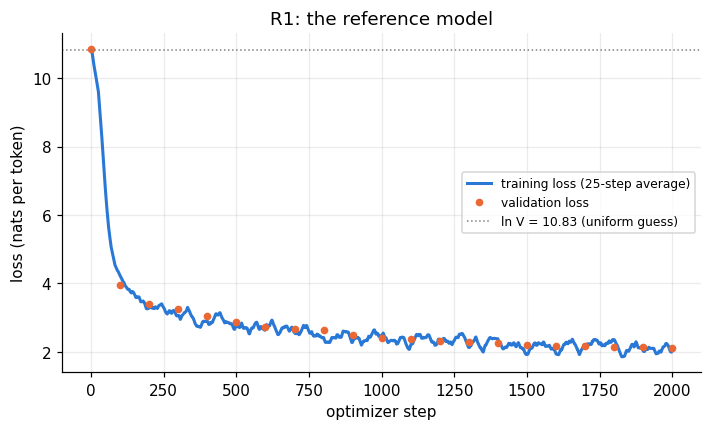

In [5]:
model_R1 = build(Config())
res_R1 = train(model_R1, steps=STEPS, data=train_tok, val=val_windows, label="R1 tied, one head")
print(f"R1: final validation loss {res_R1['final']['loss1']:.4f}, top-1 accuracy {res_R1['final']['acc1']:.2%}, "
      f"{res_R1['tok_per_s']:,.0f} tokens/s, peak memory {res_R1['peak_gib']:.2f} GiB, {res_R1['train_time_s'] / 60:.1f} min")
RESULTS["R1"] = res_R1
save_results()

plt.figure(figsize=(7.5, 4))
plt.plot([h[0] for h in res_R1["hist"]], smooth([h[1] for h in res_R1["hist"]], 25), color=C[0],
         label="training loss (25-step average)")
plt.plot([s for s, _ in res_R1["val_hist"]], [e["loss1"] for _, e in res_R1["val_hist"]], "o", color=C[1], ms=4,
         label="validation loss")
plt.axhline(math.log(V), color="grey", lw=1, ls=":", label=f"ln V = {math.log(V):.2f} (uniform guess)")
plt.xlabel("optimizer step"); plt.ylabel("loss (nats per token)"); plt.title("R1: the reference model")
plt.legend(fontsize=8)
savefig("reference_run")

**Observations.**
- The validation loss fell from 10.854 before training to **2.116** after 2,000 steps (perplexity 8.3). That is better
  than my predicted 2.2-2.6, and it was still falling at the end (2.151 → 2.116 over the last 200 steps).
- Top-1 accuracy is 52.3%: about half the time, the model's first guess is the real next token.
- The training curve is noisy (single steps between 1.95 and 3.04 late in the run), because each step sees only
  8,192 tokens, about 37 stories. The validation points always use the same 262,144 tokens and fall smoothly.
- Speed: 63,728 tokens/s, peak memory 8.15 GiB, 4.3 minutes on the L4.

## Task 1: every tensor shape, and what each dimension is

The names used in every shape:

| Symbol | Meaning | Value |
|---|---|---:|
| B | sequences in the batch | 16 |
| T | token positions per sequence | 512 |
| D | width: numbers in one token's hidden vector | 384 |
| H, hd | attention heads, and the width of each | 6, 64 |
| F | width of the feed-forward middle | 1,024 |
| V | vocabulary size: one score (logit) per entry | 50,304 |

**Predicted sizes:**
- the hidden state, (16, 512, 384) in fp32: **12 MiB**;
- the logits, (16, 512, 50,304) in bf16: **786 MiB**;
- `logits[:, :-1].reshape(-1, V)` is a **copy**, another 784.5 MiB, because the slice is not contiguous in memory.

So the logits hold $V / D = 131\times$ as many numbers as the hidden state that produced them, only to be reduced to
one loss number.

`model0` is the tied model **before any training**, built with the same seed as R1.

In [6]:
model0 = build(Config())                                    # = R1 at step 0 (same init seed, nothing trained)
trace_rows = []
def trace(name, t, meaning):
    "Record one tensor for the shape table: its name, shape, dtype, bytes if materialised, and what its axes mean."
    trace_rows.append((name, tuple(t.shape), str(t.dtype).replace("torch.", ""), t.numel() * t.element_size(), meaning))

tokens = train_tok[:B * T].view(B, T).long()                # (16, 512): the first training batch
with torch.no_grad(), torch.autocast("cuda", dtype=torch.bfloat16):
    hidden = model0(tokens, doc=doc_ids(tokens), trace=trace)                                  # (B, T, D)
    logits = model0.head(hidden)                                                               # (B, T, V)
    trace("logits = model.head(hidden)", logits, "(B, T, V): one raw score per vocabulary entry, at every position")
    z_shift = logits[:, :-1]
    trace("logits[:, :-1]   (a view)", z_shift, "(B, T-1, V): drop the last position: nothing follows it")
    z_flat = z_shift.reshape(-1, V)
    trace("logits[:, :-1].reshape(-1, V)", z_flat, "(B*(T-1), V): one row per prediction")
    trace("tokens[:, 1:]   (a view)", tokens[:, 1:], "(B, T-1): drop the first token: nothing predicts it")
    tgt = make_targets(tokens, 1)
    trace("targets = make_targets(tokens, 1)", tgt, "(B, T-1): tokens[:, 1:] with -100 where a pair must not count")
    t_flat = tgt.reshape(-1)
    trace("targets.reshape(-1)", t_flat, "(B*(T-1),): the true next token for each row of logits")
    per_tok = F.cross_entropy(z_flat.float(), t_flat, ignore_index=IGNORE, reduction="none")
    trace("per-token loss (reduction='none')", per_tok, "(B*(T-1),): -log p(true next token), 0 where ignored")
    n_valid = (t_flat != IGNORE).sum()
    loss = per_tok.sum() / n_valid
    trace("loss = sum / number of scored targets", loss, "(): the one number the optimiser pushes down")

print(f"B = {B}, T = {T}, D = {D}, H = {model0.cfg.n_head}, hd = {D // model0.cfg.n_head}, F = {model0.cfg.d_ff}, V = {V:,}\n")
print(f"{'tensor':<46}{'shape':<22}{'dtype':<10}{'MiB':>9}   what the dimensions are")
for name, shp, dt, nbytes, meaning in trace_rows:
    print(f"{name:<46}{str(shp):<22}{dt:<10}{nbytes / 2**20:>9.2f}   {meaning}")
print(f"\nlogits[:, :-1] is contiguous: {z_shift.is_contiguous()}  ->  reshape had to copy: "
      f"{z_flat.data_ptr() != logits.data_ptr()}")
print(f"logits / hidden: {logits.numel() / hidden.numel():.1f}x as many numbers (V / D = {V / D:.1f})")
print(f"scored targets: {n_valid.item():,} of {t_flat.numel():,} (the rest follow an <eot>); untrained loss {loss.item():.4f}")
RESULTS["task1"] = {"logits_shape": list(logits.shape), "logits_mib": logits.numel() * 2 / 2**20,
                    "hidden_mib": hidden.numel() * 4 / 2**20, "ratio_elements": logits.numel() / hidden.numel()}
del logits, z_shift, z_flat, per_tok

B = 16, T = 512, D = 384, H = 6, hd = 64, F = 1024, V = 50,304

tensor                                        shape                 dtype           MiB   what the dimensions are
tokens                                        (16, 512)             int64          0.06   (B, T): B sequences in the batch, T token positions per sequence
x = embedding(tokens)                         (16, 512, 384)        float32       12.00   (B, T, D): one D-wide vector per token, the residual stream
attention mask (same doc, causal)             (16, 1, 512, 512)     bool           4.00   (B, 1, T, T): query t may see key s; 1 = shared by heads
block 0  qkv = Linear(D, 3D)                  (16, 512, 1152)       bfloat16      18.00   (B, T, 3D): query, key and value for every token, packed
block 0  q (also k, v), after RoPE            (16, 6, 512, 64)      bfloat16       6.00   (B, H, T, hd): split into H heads of width hd = D/H
block 0  attention output per head            (16, 6, 512, 64)      bfloat16     

**Observations.**
- Every shape and size matched the prediction: hidden state (16, 512, 384) = 12.0 MiB, logits (16, 512, 50,304) =
  786.0 MiB. The logits hold **131×** as many numbers as the hidden state (65× the bytes, since the logits are bf16
  and the hidden state fp32).
- `logits[:, :-1]` is a view, but not contiguous, so `.reshape(-1, V)` **copied** it: another 784.5 MiB, only to
  line the rows up. Slicing the hidden state *before* the head gives the same rows for 12 MiB; the chunked loss in
  Task 7 does that.
- The dtypes show where mixed precision happens: the residual stream stays float32, while every matrix product's
  output is bfloat16.
- The attention mask (16, 1, 512, 512) is 4 MiB of booleans. The 1 means all 6 heads share it.
- 8,129 of the 8,176 targets are scored. The other 47 follow an `<eot>`. Untrained loss on this batch: 10.855.

## Task 2: verify the shift with strings, not ids

The text supervises itself: **the target at position $t$ is the token at position $t+1$.**

| position | 0 | 1 | 2 | 3 |
|---|---|---|---|---|
| input | `Once` | ` upon` | ` a` | ` time` |
| target | ` upon` | ` a` | ` time` | `,` |

A wall of integers hides an off-by-one; a column of words shows it at once. The cell prints inputs and targets as
strings, then checks the whole batch: every scored target must equal the next input.

**Prediction:** every target string equals the input one row below it. The only unscored targets are those right
after an `<eot>` (the first word of the next, unrelated story), so their number equals the number of `<eot>`
tokens among the inputs. At the end, the two classic bugs are printed the same way.

In [7]:
def pair_status(row_tok, p, y):
    "Verdict for the pair at position p of one row: does target y equal the token that really comes next?"
    x, nxt = int(row_tok[p]), int(row_tok[p + 1])
    if y == IGNORE:
        if x == PAD or nxt == PAD:
            return "not scored: padding"
        if x == EOT:
            return "not scored: next token starts a new story"
        return "not scored"
    if y != nxt:
        return "MISALIGNED"
    return "aligned, but crosses into the next story" if x == EOT else "ok, target = next input"

def show_pairs(row_tok, row_tgt, positions, title):
    "Print input and target strings side by side. row_tok (T,) ids; row_tgt (T-1,) targets from make_targets."
    print(title)
    print(f"  {'pos':>4}  {'input id':>8}  {'input string':<17}    {'target id':>9}  {'target string':<17}  check")
    for p in positions:
        x, y = int(row_tok[p]), int(row_tgt[p])
        print(f"  {p:>4}  {x:>8}  {tok_str(x):<17} -> {y:>9}  {tok_str(y):<17}  {pair_status(row_tok, p, y)}")

row, row_tgt = tokens[0], tgt[0]
e = int((row[:-1] == EOT).nonzero()[0])                    # first <eot> of row 0 that has a successor
show_pairs(row, row_tgt, range(0, 12), "Row 0, positions 0-11:")
show_pairs(row, row_tgt, range(max(0, e - 3), min(T - 1, e + 4)), f"\nRow 0 around its first <eot> (position {e}):")

inp = tokens[:, :-1]                                       # (16, 511)
valid = tgt != IGNORE
n_valid, n_all = valid.sum().item(), tgt.numel()
n_aligned = ((tgt == tokens[:, 1:]) & valid).sum().item()
n_eot_inputs = (inp == EOT).sum().item()
print(f"\nWhole batch: {n_aligned:,} of {n_valid:,} scored targets equal the next input token (misaligned: {n_valid - n_aligned})")
print(f"unscored targets: {n_all - n_valid} = <eot> tokens among the inputs: {n_eot_inputs}  "
      f"({'match' if n_all - n_valid == n_eot_inputs else 'MISMATCH'})")

print("\nWhat the two classic bugs look like as strings:")
print("BUG A, no shift: cross_entropy(logits.reshape(-1, V), tokens.reshape(-1))")
for p in range(5):
    print(f"  pos {p}: input {tok_str(row[p]):<12} -> target {tok_str(row[p]):<12}  the token it already holds")
print("BUG B, shifted the wrong way: cross_entropy(logits[:, 1:].reshape(-1, V), tokens[:, :-1].reshape(-1))")
for p in range(1, 6):
    print(f"  pos {p}: input {tok_str(row[p]):<12} -> target {tok_str(row[p - 1]):<12}  the token before it, already seen")
RESULTS["task2"] = {"aligned": n_aligned, "scored": n_valid, "unscored": n_all - n_valid, "eot_inputs": n_eot_inputs}

Row 0, positions 0-11:
   pos  input id  input string         target id  target string      check
     0      3198  'One'             ->      1110  ' day'             ok, target = next input
     1      1110  ' day'            ->        11  ','                ok, target = next input
     2        11  ','               ->       257  ' a'               ok, target = next input
     3       257  ' a'              ->      1310  ' little'          ok, target = next input
     4      1310  ' little'         ->      2576  ' girl'            ok, target = next input
     5      2576  ' girl'           ->      3706  ' named'           ok, target = next input
     6      3706  ' named'          ->     20037  ' Lily'            ok, target = next input
     7     20037  ' Lily'           ->      1043  ' found'           ok, target = next input
     8      1043  ' found'          ->       257  ' a'               ok, target = next input
     9       257  ' a'              ->     17598  ' needle'      

**Observations.**
- **All 8,129 scored targets equal the next input token; 0 are misaligned.**
- The 47 unscored targets are exactly the 47 `<eot>` inputs. The pair `<eot>` → `'Once'` at position 162 of row 0
  is the only kind of pair the harness drops.
- The two bug tables show why strings beat ids. In bug A every target is the same word as its input (`'One'` →
  `'One'`). In bug B every target is the word before it (`' day'` → `'One'`). Both are obvious in words; as ids they
  are just plausible integers.

## Task 3: mask padding, and watch the count change

When stories are batched **one per row**, short rows are filled with `<pad>` up to the longest row. A pad is not a
prediction, so every pair whose input or target is a pad is set to `-100`, and `F.cross_entropy(...,
ignore_index=-100)` leaves it out of the sum **and out of the count** it divides by.

Four validation stories are padded to the longest one.

**Hand-checkable counts:**
- with the pads counted: 4 × (longest length − 1);
- with them masked: the sum of (each story's length − 1).

**Three ways to average:**
1. **masked (correct):** the real losses divided by the number of real targets;
2. **pads counted:** every loss, real and pad, divided by every position;
3. **wrong denominator:** the real losses divided by every position. The pads are masked from the sum but the
   division is still by all positions, so the loss shrinks by the fraction of the batch that is real.

**Predictions.**
- **Untrained model:** a pad target costs about as much as any other token, so "masked" and "counted" are almost
  equal. The mask changes the count, not the loss.
- **Trained R1:** R1 never saw a `<pad>` in training, so it gives `<pad>` almost no probability. Counting the pads
  makes the loss much **worse**. (A model *trained* with pads counted learns "pad follows pad" and its loss looks
  better instead; Part 3 trains that model.)

In [8]:
want = [48, 96, 144, 192]                                   # target story lengths, tokens including <eot>
picked = [next(d for d in val_docs if abs(len(d) - w) <= 6) for w in want]
lens4 = [len(d) for d in picked]
Tm = max(lens4)
pad_batch = torch.full((4, Tm), PAD, dtype=torch.long)
for i, d in enumerate(picked):
    pad_batch[i, :len(d)] = torch.from_numpy(d.astype(np.int64))
pad_batch = pad_batch.cuda()                                # (4, Tm), one story per row, right-padded
print(f"story lengths (incl. <eot>): {lens4}, padded to {Tm}")
print(f"hand prediction: pads counted = 4 x ({Tm} - 1) = {4 * (Tm - 1)};  pads masked = sum(l - 1) = {sum(l - 1 for l in lens4)}")

def padded_losses(model, tok):
    "Loss of a right-padded batch averaged three ways, plus the target counts. tok (b, Tm) -> dict."
    with torch.no_grad(), torch.autocast("cuda", dtype=torch.bfloat16):
        z = model.head(model(tok, doc=doc_ids(tok)))[:, :-1].reshape(-1, V).float()        # (b*(Tm-1), V)
    t_mask = make_targets(tok, 1, mask_boundary=False).reshape(-1)                      # pads -> -100
    t_all = make_targets(tok, 1, mask_pad=False, mask_boundary=False).reshape(-1)       # every position counted
    per = F.cross_entropy(z, t_all, reduction="none")                                   # (b*(Tm-1),)
    real = t_mask != IGNORE
    n_real, n_all = real.sum().item(), t_all.numel()
    return {"n_real": n_real, "n_all": n_all,
            "masked": F.cross_entropy(z, t_mask, ignore_index=IGNORE).item(),
            "counted": per.mean().item(),
            "wrong_den": per[real].sum().item() / n_all,
            "pad_targets_only": per[~real].mean().item()}

r3 = {"untrained": padded_losses(model0, pad_batch), "trained R1": padded_losses(model_R1, pad_batch)}
labels = [("contributing targets, pads masked", "n_real", "d"), ("contributing targets, pads counted", "n_all", "d"),
          ("loss, pads masked (correct)", "masked", "f"), ("loss, pads counted", "counted", "f"),
          ("loss, pads masked but divided by all positions", "wrong_den", "f"),
          ("mean loss of the pad targets alone", "pad_targets_only", "f")]
print(f"\n{'':<50}{'untrained':>12}{'trained R1':>13}")
for lab, key, kind in labels:
    a, b = r3["untrained"][key], r3["trained R1"][key]
    print(f"{lab:<50}" + (f"{a:>12,}{b:>13,}" if kind == "d" else f"{a:>12.4f}{b:>13.4f}"))

short = int(np.argmin(lens4))
show_pairs(pad_batch[short], make_targets(pad_batch, 1, mask_boundary=False)[short],
           range(lens4[short] - 4, lens4[short] + 2), f"\nRow {short} (the shortest story) where the story ends and padding starts:")
RESULTS["task3"] = r3

story lengths (incl. <eot>): [50, 102, 145, 192], padded to 192
hand prediction: pads counted = 4 x (192 - 1) = 764;  pads masked = sum(l - 1) = 485

                                                     untrained   trained R1
contributing targets, pads masked                          485          485
contributing targets, pads counted                         764          764
loss, pads masked (correct)                            10.8289       1.6241
loss, pads counted                                     10.3318       5.5366
loss, pads masked but divided by all positions          6.8744       1.0310
mean loss of the pad targets alone                      9.4678      12.3378

Row 0 (the shortest story) where the story ends and padding starts:
   pos  input id  input string         target id  target string      check
    46       383  ' The'            ->       886  ' end'             ok, target = next input
    47       886  ' end'            ->        13  '.'                ok, target =

**Observations.**
- The counts matched the hand prediction exactly: **764 targets with pads counted, 485 with pads masked** (stories
  of 50, 102, 145 and 192 tokens).
- The wrong denominator matched too: 10.8289 × 485 / 764 = 6.8744 (untrained) and 1.6241 × 485 / 764 = 1.0310
  (trained). It reports a loss 37% too low, only because of how much of this batch is padding.
- **Untrained, my prediction was wrong.** Counting the pads *lowered* the loss by 0.50 (10.83 → 10.33), because a pad
  target cost only 9.47, not the ~10.8 of a random guess.
  - Almost all pad targets (276 of 279) are `<pad>` after `<pad>`, which means "repeat the token you are reading".
  - A tied model already leans that way at step 0: its output matrix *is* its input embedding, so the token being
    read gets a higher score.
  - Part 3 shows the same effect: the no-shift run starts at 8.95 instead of 10.85.
- **Trained R1, as predicted.** Counting the pads raised the loss from **1.62 to 5.54**. R1 never saw a `<pad>`, so
  each pad target costs 12.3, worse than a uniform guess.
- So counting padding can make the loss look better or worse. Either way, the number no longer measures the text.

## Task 4: pack two documents, mask the boundary

**Packing** joins stories into one sequence, so no position is wasted on padding: `story A <eot> story B <eot>`. It
creates one bad training pair at the join. The input is A's `<eot>`, and the target is B's first word. Nothing in A
predicts how an unrelated story begins.

Three versions of the same packed sequence:

| | Attention | The boundary pair |
|---|---|---|
| (a) naive | B can see A | scored |
| (b) boundary masked | B can see A | not scored |
| (c) fully fixed | B sees only B | not scored |

**Why the loss changes.** Masking removes one term from the average. If that term was **above** the average, the
average goes down; if it was below, the average goes up. The cell prints the boundary pair's own loss so you can
see which.

**Predictions.**
- **Untrained:** the boundary pair costs about the same as every other pair, so (a), (b) and (c) agree to 3 or 4
  decimals.
- **Trained R1:** R1 was trained with the boundary masked, so it was never asked what follows an `<eot>`. That pair
  should cost much more than average, and masking it should lower the loss visibly. R1 also never looked across a
  story boundary in training, so letting B see A in (a) and (b) should raise B's loss compared with (c), most of
  all for B's first few words.

In [9]:
cands = [d for d in val_docs if 40 <= len(d) <= 100]
doc_A, doc_B = cands[0], cands[1]
packed = torch.from_numpy(np.concatenate([doc_A, doc_B]).astype(np.int64))[None].cuda()   # (1, L)
LA, L = len(doc_A), packed.shape[1]
bpos = LA - 1                                              # A's <eot>; its target packed[LA] is B's first token
print(f"story A: {LA} tokens, story B: {len(doc_B)} tokens, packed length {L}")
print("A:", enc.decode(doc_A[:-1].tolist())[:150], "...")
print("B:", enc.decode(doc_B[:-1].tolist())[:150], "...")
show_pairs(packed[0], make_targets(packed, 1, mask_boundary=False)[0], range(bpos - 3, bpos + 4),
           "\nThe join, boundary NOT masked (version a):")
show_pairs(packed[0], make_targets(packed, 1)[0], range(bpos - 3, bpos + 4), "\nThe join, boundary masked (versions b, c):")

def packed_report(model, tok):
    "Losses of one packed sequence in the three versions (a), (b), (c), the boundary pair's loss, and B's losses."
    la = per_token_losses(model, tok, doc_mask=False, mask_boundary=False)[0]    # (L-1,) (a)
    lb = per_token_losses(model, tok, doc_mask=False, mask_boundary=True)[0]     # (b)
    lc = per_token_losses(model, tok, doc_mask=True, mask_boundary=True)[0]      # (c)
    return {"n_a": int((~la.isnan()).sum()), "loss_a": la.nanmean().item(),
            "n_b": int((~lb.isnan()).sum()), "loss_b": lb.nanmean().item(), "loss_c": lc.nanmean().item(),
            "l_boundary": la[bpos].item(),
            "B_first8_b": lb[bpos + 1:bpos + 9].nanmean().item(), "B_first8_c": lc[bpos + 1:bpos + 9].nanmean().item()}

r4 = {"untrained": packed_report(model0, packed), "trained R1": packed_report(model_R1, packed)}
rows4 = [("(a) naive: targets scored", "n_a", "d"), ("(a) naive: loss", "loss_a", "f"),
         ("loss of the boundary pair alone (<eot> -> B's first word)", "l_boundary", "f"),
         ("(b) boundary masked: targets scored", "n_b", "d"), ("(b) boundary masked: loss", "loss_b", "f"),
         ("(c) boundary masked + B sees only B: loss", "loss_c", "f"),
         ("B's first 8 targets, (b) B can see A", "B_first8_b", "f"),
         ("B's first 8 targets, (c) B sees only B", "B_first8_c", "f")]
print(f"\n{'':<60}{'untrained':>12}{'trained R1':>13}")
for lab, key, kind in rows4:
    a, b = r4["untrained"][key], r4["trained R1"][key]
    print(f"{lab:<60}" + (f"{a:>12,}{b:>13,}" if kind == "d" else f"{a:>12.4f}{b:>13.4f}"))
for k, r in r4.items():
    print(f"{k}: masking the boundary moved the loss by {r['loss_b'] - r['loss_a']:+.4f} "
          f"(the boundary pair cost {r['l_boundary']:.3f} vs an average of {r['loss_a']:.3f})")
RESULTS["task4"] = r4
save_results()

story A: 83 tokens, story B: 50 tokens, packed length 133
A: Spot. Spot saw the shiny car and said, "Wow, Kitty, your car is so bright and clean!" Kitty smiled and replied, "Thank you, Spot. I polish it every da ...
B: Once upon a time, there was an old man. He liked to read magazines. One day, he saw two birds fighting outside his window. He thought it was not nice  ...

The join, boundary NOT masked (version a):
   pos  input id  input string         target id  target string      check
    79      1266  ' best'           ->      2460  ' friends'         ok, target = next input
    80      2460  ' friends'        ->        13  '.'                ok, target = next input
    81        13  '.'               ->     50256  <eot>              ok, target = next input
    82     50256  <eot>             ->      7454  'Once'             aligned, but crosses into the next story
    83      7454  'Once'            ->      2402  ' upon'            ok, target = next input
    84      2402  ' upon'

**Observations.**
- Masking the boundary removes exactly one scored target (132 → 131), and the loss moved the way the rule says:
  - **untrained:** the boundary pair cost 10.69, a little *below* the average of 10.87, so masking it raised the loss
    by 0.0013;
  - **trained R1:** it cost **14.31**, far *above* the average of 2.42, so masking it lowered the loss from **2.417
    to 2.326**. R1 was never trained on what follows an `<eot>`, so that prediction is far worse than a uniform
    guess.
- Check: removing one term from the average gives (132 × 2.4168 − 14.3065) / 131 = 2.3260, the measured value.
- **Blocking attention across the boundary mattered even more** for the trained model: 2.326 → **2.057**. That change
  can only come from story B, because story A comes first and sees the same tokens in both versions.
  - Story B's first 8 targets ("Once upon a time, there was an old man") cost **3.07** when B could see story A.
  - They cost **0.71** when it could not.
  - R1 was trained never to look across stories, so a previous story in view confuses it.
- Untrained, the three versions agree to within 0.02, as predicted.

## Task 5: perplexity, and why an untrained model sits near $V$

**Perplexity** is the loss turned back into a count: $\text{PPL} = e^{\text{loss}}$. It is the number of equally
likely options the model is effectively choosing between. A loss of 2.30 is a fair 10-way guess ($e^{2.30} = 10$).

An untrained model has no idea which token comes next, so it spreads its probability almost evenly over all
50,304 entries. Each correct token then gets probability about $1/V$, the loss is about $\ln V = \ln 50{,}304 =
10.83$, and the perplexity is about $V$.

**Prediction:** perplexity close to 50,304, a little above it (about 1.08 × V), because random starting scores are
not perfectly equal. If it is far from $V$, the harness has a bug: a wrong shift, a wrong mask or a wrong
denominator.

**What this check catches.** It is a cheap first test, not proof:
- the **wrong denominator** of Task 3 makes the perplexity far smaller than $V$: caught;
- **double softmax** (feeding probabilities into `cross_entropy`, which expects raw scores) still gives about $V$
  at step 0: **not caught**. The training would be broken, but the check passes.

In [10]:
ev_win = val_windows[:64]
model0_untied = build(Config(tie=False))
r5 = {}
for name, m in [("tied (R1 at step 0)", model0), ("untied", model0_untied)]:
    ev = evaluate(m, ev_win)
    r5[name] = ev["loss1"]
    print(f"untrained {name:<20} loss {ev['loss1']:.4f}   perplexity {math.exp(ev['loss1']):>8,.0f}   "
          f"= {math.exp(ev['loss1']) / V:.3f} x V   (ln V = {math.log(V):.4f}, V = {V:,})")

tok = val_windows[:16].long()
with torch.no_grad(), torch.autocast("cuda", dtype=torch.bfloat16):
    z = model0.head(model0(tok, doc=doc_ids(tok))).float()[:, :-1].reshape(-1, V)       # (16*511, V)
t1 = make_targets(tok, 1).reshape(-1)
checks = [("correct harness", F.cross_entropy(z, t1, ignore_index=IGNORE).item()),
          ("wrong denominator (padded batch of Task 3)", r3["untrained"]["wrong_den"]),
          ("double softmax: cross_entropy(softmax(logits))", F.cross_entropy(z.softmax(-1), t1, ignore_index=IGNORE).item())]
del z
print(f"\n{'harness, untrained model':<50}{'loss':>8}{'PPL / V':>10}   caught by 'PPL close to V'?")
for name, l in checks:
    ratio = math.exp(l) / V
    verdict = "reference" if name == "correct harness" else ("yes" if abs(math.log(ratio)) > 0.2 else "NO, looks healthy")
    print(f"{name:<50}{l:>8.4f}{ratio:>10.3f}   {verdict}")
l = res_R1["final"]["loss1"]
print(f"\nafter training, R1: validation loss {l:.4f}, perplexity {math.exp(l):.2f} (it was about {V:,} at step 0)")
RESULTS["task5"] = {"measured": r5, "checks": checks, "trained_ppl_R1": math.exp(l)}
save_results()

untrained tied (R1 at step 0)  loss 10.8602   perplexity   52,060   = 1.035 x V   (ln V = 10.8258, V = 50,304)
untrained untied               loss 10.8877   perplexity   53,514   = 1.064 x V   (ln V = 10.8258, V = 50,304)

harness, untrained model                              loss   PPL / V   caught by 'PPL close to V'?
correct harness                                    10.8543     1.029   reference
wrong denominator (padded batch of Task 3)          6.8744     0.019   yes
double softmax: cross_entropy(softmax(logits))     10.8258     1.000   NO, looks healthy

after training, R1: validation loss 2.1161, perplexity 8.30 (it was about 50,304 at step 0)


**Observations.**
- Untrained perplexity:
  - **52,060 = 1.035 × V** for the tied model;
  - 53,514 = 1.064 × V for the untied one.
- Both are close to V = 50,304 and a little above it, as predicted. Both are a bit below my estimate of 1.08 × V;
  the exact excess depends on the random starting weights.
- **The check caught the wrong denominator** (perplexity 0.019 × V).
- **It did not catch double softmax.** That harness gives exactly ln V = 10.8258, a perplexity of exactly V.
  Softmax outputs are all close to 0, and cross-entropy reads near-equal scores as a perfect uniform guess. So
  "perplexity ≈ V at step 0" is a cheap first test, not proof that the harness is right.
- After training, R1's perplexity is **8.30**: it chooses between about 8 equally likely tokens, down from 50,304.

## Task 6: tied vs untied head

The input embedding and the output head have the same shape, (50,304, 384): one row per token. **Tying** uses one
matrix for both jobs, reading tokens in and scoring tokens out.

**Prediction:** untied − tied = 50,304 × 384 = **19,316,736** parameters. In the untied model the head alone is
39% of all parameters.

Two practical traps checked below:
- **Counting tied weights.** `model.parameters()` lists the shared matrix once. `model.state_dict()` lists it under
  both of its names, so counting with `state_dict` reports the tied model as if it were untied.
- **Every row of the head gets a gradient.** The loss pushes up the score of the correct token and pushes down
  every other token's score. So after one batch all 50,304 rows of the head have a nonzero gradient, even rows of
  tokens that never occur in TinyStories. The embedding gets a gradient only for the tokens actually read. This is
  why the head is expensive.

In [11]:
cfgs6 = [("tied, one head (R1)", Config()), ("untied, one head", Config(tie=False)),
         ("tied + parallel t+2 head (R2)", Config(head2="dense")),
         ("tied + sequential t+2 head (R3)", Config(head2="sequential"))]
print(f"{'model':<34}{'parameters()':>14}{'state_dict()':>14}{'own head 1':>12}{'head 2':>12}")
counts6 = {}
for name, cfg in cfgs6:
    c = count_params(LM(cfg))
    counts6[name] = c
    print(f"{name:<34}{c['total']:>14,}{c['state_dict_total']:>14,}{c['head1_own']:>12,}{c['head2']:>12,}")
tied, untied = counts6["tied, one head (R1)"], counts6["untied, one head"]
print(f"\nuntied - tied = {untied['total'] - tied['total']:,};  V x D = {V} x {D} = {V * D:,}")
print(f"the untied head is {untied['head1_own'] / untied['total']:.1%} of the untied model")
print(f"tied model, state_dict() count - parameters() count = {tied['state_dict_total'] - tied['total']:,} (counted twice)")

m = build(Config(tie=False))
tok = train_tok[:B * T].view(B, T).long()
with torch.autocast("cuda", dtype=torch.bfloat16):
    harness_losses(m, tok)["total"].backward()
head_rows = (m.lm_head.weight.grad != 0).any(dim=1).sum().item()
emb_rows = (m.emb.weight.grad != 0).any(dim=1).sum().item()
t1 = make_targets(tok, 1)
print(f"\nafter one batch of {B * T:,} tokens (untied model):")
print(f"  output-head rows with a nonzero gradient: {head_rows:,} of {V:,}")
print(f"  different tokens that are actually targets in the batch: {t1[t1 != IGNORE].unique().numel():,}")
print(f"  embedding rows with a nonzero gradient: {emb_rows:,} (= different input tokens: {tok.unique().numel():,})")
del m
RESULTS["task6"] = {"counts": counts6, "head_rows_with_grad": head_rows, "emb_rows_with_grad": emb_rows}
save_results()

model                               parameters()  state_dict()  own head 1      head 2
tied, one head (R1)                   29,938,560    49,255,296           0           0
untied, one head                      49,255,296    49,255,296  19,316,736           0
tied + parallel t+2 head (R2)         49,255,296    68,572,032           0  19,316,736
tied + sequential t+2 head (R3)       32,004,864    51,321,600           0   2,066,304

untied - tied = 19,316,736;  V x D = 50304 x 384 = 19,316,736
the untied head is 39.2% of the untied model
tied model, state_dict() count - parameters() count = 19,316,736 (counted twice)

after one batch of 8,192 tokens (untied model):
  output-head rows with a nonzero gradient: 50,304 of 50,304
  different tokens that are actually targets in the batch: 923
  embedding rows with a nonzero gradient: 924 (= different input tokens: 925)


**Observations.**
- The counts are as predicted: **tied 29,938,560, untied 49,255,296**. The difference is 19,316,736 = 50,304 × 384.
  The untied head is 39.2% of its model.
- The `state_dict` trap is real: `state_dict()` reports the tied model as 49,255,296, because the shared matrix is
  counted under both of its names.
- The Part 2 heads differ a lot in cost. The parallel head adds a full 19.3M (R2 = 49.3M), the sequential head 2.1M
  (R3 = 32.0M).
- After one batch, **all 50,304 rows of the head had a nonzero gradient**, although only 923 different tokens were
  targets.
- **A surprise:** the embedding got gradient in 924 rows, one fewer than the 925 different input tokens. Rebuilding
  the same batch locally shows the missing row is **`<eot>`**:
  - every `<eot>` input has its target masked, because the next token starts a new story;
  - document-aware attention stops every later token from looking back at it;
  - so its embedding influences no loss at all.

  With the correct harness, the input embedding of `<eot>` is never trained. In the tied model that row learns only
  from its other job, predicting the end of a story.

## Task 7: peak memory, ordinary vs chunked cross-entropy

**Ordinary cross-entropy** first builds the whole table of scores: one row per position, one column per vocabulary
entry. For our batch that is 8,176 × 50,304 = 411 million numbers, **1.5 GiB in fp32**. It keeps the table (and a few
copies of it) until the backward pass.

**Chunked cross-entropy** notices that each position's loss needs only its own row. So it:
1. takes 1,024 positions at a time, computes their rows, turns them into losses, keeps **one number per row**, and
   throws the rows away before the next 1,024;
2. in the backward pass, recomputes each chunk's rows once more to get the gradients.

The loss is the same sum, added in a different order. The price is one extra matrix multiply per chunk. It is like
grading 8,000 exam papers a stack at a time instead of spreading all of them on the desk at once. The code is
`ChunkedCrossEntropy` in `lmharness.py`.

**Peak memory** is the most GPU memory the tensors used at any one moment (`torch.cuda.max_memory_allocated`).

**Predictions.**
- **Ordinary:** a few copies of the 1.5 GiB table, about 4-5 GiB.
- **Chunked:** a few 1,024-row tables of 0.2 GiB each, about 0.5 GiB.
- So about **9× less memory**, the same loss, and somewhat slower.
- Ordinary memory grows with the number of positions; chunked stays almost flat. So with more positions the gap
  grows until the ordinary version runs out of memory.

In [12]:
tok = train_tok[:B * T].view(B, T).long()
with torch.no_grad(), torch.autocast("cuda", dtype=torch.bfloat16):
    hid = model_R1(tok, doc=doc_ids(tok))                                   # (16, 512, 384)
h_in = hid[:, :-1].reshape(-1, D).float().contiguous()                      # (8176, 384): the rows of logits[:, :-1]
y_in = make_targets(tok, 1).reshape(-1)                                     # (8176,)
W_in = model_R1.lm_head.weight.detach().clone()                             # (50304, 384)
del hid

def loss_and_grads(fn, h, W, y):
    "Forward + backward of fn(h, W, y) on fresh copies; returns (loss, gradient of h, gradient of W)."
    hh, WW = h.clone().requires_grad_(True), W.clone().requires_grad_(True)
    l = fn(hh, WW, y)
    l.backward()
    return l.item(), hh.grad, WW.grad

chunked = lambda c: (lambda h, W, y: chunked_cross_entropy(h, W, y, c))
rel = lambda a, b: ((a - b).norm() / b.norm()).item()
with no_tf32():
    lo, gho, gWo = loss_and_grads(ordinary_cross_entropy, h_in, W_in, y_in)
    lc, ghc, gWc = loss_and_grads(chunked(1024), h_in, W_in, y_in)
print(f"same loss? ordinary {lo:.8f}, chunked {lc:.8f}, difference {abs(lo - lc):.1e}  (fp32)")
print(f"same gradients? relative difference: hidden {rel(ghc, gho):.1e}, head weights {rel(gWc, gWo):.1e}  (fp32)")
del gho, gWo, ghc, gWc

def measure(fn, h, W, y, reps=3):
    """Peak extra GPU memory (MiB) and median time (ms) of one forward + backward of fn(h, W, y) in bf16 autocast.
    Returns None if it runs out of memory. Example: measure(ordinary_cross_entropy, h, W, y)['peak_mib']"""
    peaks, times = [], []
    try:
        for r in range(reps + 1):                            # r = 0 is a warm-up
            hh, WW = h.detach().clone().requires_grad_(True), W.detach().clone().requires_grad_(True)
            gc.collect(); torch.cuda.synchronize(); torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
            base = torch.cuda.memory_allocated()
            t0 = time.perf_counter()
            with torch.autocast("cuda", dtype=torch.bfloat16):
                loss = fn(hh, WW, y)
            loss.backward()
            torch.cuda.synchronize()
            if r > 0:
                times.append(time.perf_counter() - t0)
                peaks.append(torch.cuda.max_memory_allocated() - base)
            lv = loss.item()
            del loss, hh, WW
    except torch.cuda.OutOfMemoryError:
        return None
    finally:
        gc.collect(); torch.cuda.empty_cache()
    return {"peak_mib": max(peaks) / 2**20, "ms": statistics.median(times) * 1e3, "loss": lv}

m_ord = measure(ordinary_cross_entropy, h_in, W_in, y_in)
m_chk = measure(chunked(1024), h_in, W_in, y_in)
ratio7 = m_ord["peak_mib"] / m_chk["peak_mib"]
print(f"\nthe loss alone, forward + backward, {h_in.shape[0]:,} positions:")
print(f"  ordinary cross-entropy:     peak {m_ord['peak_mib'] / 1024:5.2f} GiB, {m_ord['ms']:6.1f} ms")
print(f"  chunked, 1,024 per chunk:   peak {m_chk['peak_mib'] / 1024:5.2f} GiB, {m_chk['ms']:6.1f} ms")
print(f"  ratio: {ratio7:.1f}x less memory, {m_chk['ms'] / m_ord['ms']:.2f}x the time")
RESULTS["task7"] = {"N": h_in.shape[0], "ordinary": m_ord, "chunked_1024": m_chk, "ratio": ratio7,
                    "fp32_loss_diff": abs(lo - lc)}
save_results()

same loss? ordinary 1.91024923, chunked 1.91024947, difference 2.4e-07  (fp32)
same gradients? relative difference: hidden 2.2e-05, head weights 8.4e-07  (fp32)

the loss alone, forward + backward, 8,176 positions:
  ordinary cross-entropy:     peak  3.87 GiB,   63.5 ms
  chunked, 1,024 per chunk:   peak  0.43 GiB,  150.4 ms
  ratio: 9.1x less memory, 2.37x the time


### Task 7, continued: more positions, and the whole training step

The same measurement for more and more positions (random inputs): 8,192 is our batch, 131,072 is a single 128K-token
sequence. Then the full training step (forward, backward, optimizer update) at growing batch sizes, where the peak
also includes the model, the optimizer and the layers' activations.

**Prediction:** the ordinary loss runs out of memory before 65,536 positions on the L4; chunked keeps going. In the
full step the saving is smaller at our batch of 16 (the rest of the step costs the same in both), and the ordinary
step runs out of memory first as the batch grows.

 positions  ordinary GiB  chunked GiB   ratio
     2,048          1.00         0.42     2.4
     4,096          1.96         0.42     4.6
     8,192          3.88         0.43     9.1
    16,384          7.72         0.43    17.9
    32,768         15.41         0.47    33.0
    65,536 out of memory         0.54       -
   131,072 out of memory         0.68       -


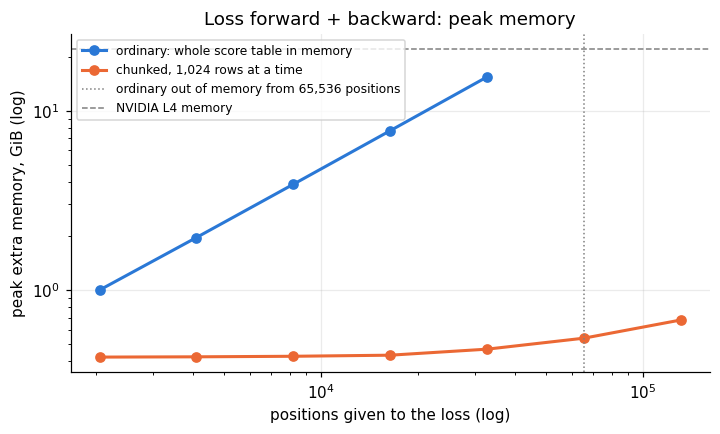


full training step:
 batch   tokens  ordinary GiB  chunked GiB  ordinary tok/s  chunked tok/s
    16    8,192          5.87         2.43          64,568         41,437
    32   16,384         10.76         3.51          61,476         40,414
    64   32,768         20.54         5.65          43,544         38,587
   128   65,536 out of memory         9.95               -         37,854


In [13]:
print(f"{'positions':>10}{'ordinary GiB':>14}{'chunked GiB':>13}{'ratio':>8}")
n_sweep = []
for N in [2048, 4096, 8192, 16384, 32768, 65536, 131072]:
    h = torch.randn(N, D, device="cuda")
    y = torch.randint(0, 50257, (N,), device="cuda")
    ro = measure(ordinary_cross_entropy, h, W_in, y, reps=1)
    rc = measure(chunked(1024), h, W_in, y, reps=1)
    n_sweep.append((N, ro["peak_mib"] if ro else None, rc["peak_mib"] if rc else None))
    fo = f"{ro['peak_mib'] / 1024:>14.2f}" if ro else f"{'out of memory':>14}"
    fr = f"{ro['peak_mib'] / rc['peak_mib']:>8.1f}" if (ro and rc) else f"{'-':>8}"
    print(f"{N:>10,}{fo}{rc['peak_mib'] / 1024:>13.2f}{fr}")
    del h, y
RESULTS["task7"]["n_sweep"] = n_sweep

plt.figure(figsize=(7.5, 4))
plt.plot([r[0] for r in n_sweep if r[1]], [r[1] / 1024 for r in n_sweep if r[1]], "o-", color=C[0], ms=6,
         label="ordinary: whole score table in memory")
plt.plot([r[0] for r in n_sweep], [r[2] / 1024 for r in n_sweep], "o-", color=C[1], ms=6, label="chunked, 1,024 rows at a time")
oom = [r[0] for r in n_sweep if r[1] is None]
if oom:
    plt.axvline(oom[0], color="grey", ls=":", lw=1, label=f"ordinary out of memory from {oom[0]:,} positions")
plt.axhline(props.total_memory / 2**30, color="grey", lw=1, ls="--", label=f"{props.name} memory")
plt.xscale("log"); plt.yscale("log")
plt.xlabel("positions given to the loss (log)"); plt.ylabel("peak extra memory, GiB (log)")
plt.title("Loss forward + backward: peak memory")
plt.legend(fontsize=8)
savefig("chunked_ce_memory")

def step_peak(batch, kind, chunk=1024, steps=3):
    """Absolute peak GPU memory (GiB) and seconds per step of `steps` full training steps of a fresh tied model.
    kind 'ordinary' -> F.cross_entropy on model.head(hidden)[:, :-1];  'chunked' -> chunked_cross_entropy.
    Returns None on out-of-memory."""
    m = opt = None
    try:
        m = build(Config())
        opt = make_optimizer(m, 1e-3)
        tok = train_tok[:batch * T].view(batch, T).long()
        gc.collect(); torch.cuda.synchronize(); torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
        times = []
        for i in range(steps):
            t0 = time.perf_counter()
            with torch.autocast("cuda", dtype=torch.bfloat16):
                hidden = m(tok, doc=doc_ids(tok))                                   # (b, T, D)
                tgt = make_targets(tok, 1).reshape(-1)
                if kind == "ordinary":
                    loss = F.cross_entropy(m.head(hidden)[:, :-1].reshape(-1, V), tgt, ignore_index=IGNORE)
                else:
                    loss = chunked_cross_entropy(hidden[:, :-1].reshape(-1, D), m.lm_head.weight, tgt, chunk)
            loss.backward()
            opt.step()
            opt.zero_grad(set_to_none=True)
            torch.cuda.synchronize()
            times.append(time.perf_counter() - t0)
        return {"peak_gib": torch.cuda.max_memory_allocated() / 2**30, "s_per_step": statistics.median(times[1:])}
    except torch.cuda.OutOfMemoryError:
        return None
    finally:
        del m, opt
        gc.collect(); torch.cuda.empty_cache()

print(f"\nfull training step:\n{'batch':>6}{'tokens':>9}{'ordinary GiB':>14}{'chunked GiB':>13}{'ordinary tok/s':>16}{'chunked tok/s':>15}")
step_rows = []
for b in [16, 32, 64, 128]:
    ro, rc = step_peak(b, "ordinary"), step_peak(b, "chunked")
    step_rows.append((b, ro, rc))
    fo = f"{ro['peak_gib']:>14.2f}" if ro else f"{'out of memory':>14}"
    fc = f"{rc['peak_gib']:>13.2f}" if rc else f"{'out of memory':>13}"
    to = f"{b * T / ro['s_per_step']:>16,.0f}" if ro else f"{'-':>16}"
    tc = f"{b * T / rc['s_per_step']:>15,.0f}" if rc else f"{'-':>15}"
    print(f"{b:>6}{b * T:>9,}{fo}{fc}{to}{tc}")
RESULTS["task7"]["train_step"] = step_rows
save_results()

**Observations.**
- **Same loss and gradients.** The losses differ by 2.4e-7 in fp32, the gradients by at most 2.2e-5 relative. That is
  rounding from adding the same numbers in a different order.
- **At the training shape (8,176 positions), the loss alone peaks at 3.87 GiB ordinary vs 0.43 GiB chunked: 9.1× less
  memory**, close to the predicted 9×. The ordinary peak is 2.5 copies of the 1.53 GiB fp32 score table.
- **It is 2.4× slower** (63.5 ms → 150.4 ms). That is more than the one extra matrix multiply alone would cost; the
  rest is this plain-PyTorch version's Python loop and its extra fp32 passes over each chunk.
- **More positions:**
  - ordinary memory doubles with each doubling of positions (1.00 → 15.41 GiB from 2,048 to 32,768) and runs out of
    memory at 65,536, as predicted;
  - chunked stays between 0.42 and 0.68 GiB all the way to 131,072 positions;
  - the ratio grows from 2.4× to 33×.
- **Whole training step:**
  - at our batch of 16 the saving is smaller, 5.87 → 2.43 GiB (2.4×), because the model, optimizer and activations
    cost the same in both;
  - chunked training runs at 64% of the ordinary speed (41,437 vs 64,568 tokens/s);
  - at batch 64 the ordinary step needs 20.5 of the L4's 22 GiB and slows to 43,544 tokens/s;
  - at batch 128 the ordinary step runs out of memory, while chunked trains in 9.95 GiB at 37,854 tokens/s.

## Part 2: a second head that predicts token $t+2$

**Multi-token prediction (MTP).** The 6 layers stay shared. A second output head is added and trained to predict the
token **two** positions ahead, while head 1 keeps predicting the next one:

$$
\mathcal L_1 = \operatorname{mean}_t\, \bigl(-\log p_1(x_{t+1})\bigr), \qquad
\mathcal L_2 = \operatorname{mean}_t\, \bigl(-\log p_2(x_{t+2})\bigr), \qquad
\mathcal L = \mathcal L_1 + \mathcal L_2
$$

**Reading $\mathcal L_1$ in words.**
- At every position $t$, head 1 gives a probability to every vocabulary entry.
- $p_1(x_{t+1})$ is the probability it gave to the token that **really** came next.
- $-\log$ turns that probability into a penalty: 0 if it was certain and right, 0.69 for $p = 0.5$, 2.30 for $p =
  0.1$, 10.83 for a uniform guess.
- $\operatorname{mean}_t$ averages the penalty over every position that counts, giving one number.

Example: three positions where the true token got $p = 0.5,\ 0.1,\ 0.9$ give penalties $0.69,\ 2.30,\ 0.11$, so
$\mathcal L_1 = (0.69 + 2.30 + 0.11) / 3 = 1.03$. This is exactly the cross-entropy of Part 1, written per
position. $\mathcal L_2$ is the same for the token two ahead. Training minimises the sum.

**Two ways to build the second head.** Both are used in practice, and the difference matters:

| | **Parallel** (R2) | **Sequential** (R3) |
|---|---|---|
| used by | Meta's multi-token prediction (2024), Medusa | DeepSeek-V3 |
| head 2 reads | only $h_t$, the same hidden state as head 1 | $h_t$ **and the embedding of token $t+1$** |
| token $t+1$ during training | not given | the **true** token (teacher forcing) |
| token $t+1$ at inference | not given | head 1's own prediction |
| what it computes | its own (50,304 × 384) output matrix on $h_t$ | combine both, one extra transformer layer, then the shared output matrix |
| extra parameters | 19,316,736 | 2,066,304 |

So the parallel head must guess the word after next **without knowing the next word**. The sequential head is told
the next word, so it predicts "the next token after a known one", nearly the same job as head 1. The assignment's
wording ("a second output head predicting $t+2$") matches the parallel head, so R2 is the main answer. R3 shows
what changes with the sequential design.

**Predictions.**
1. **Step 0:** both heads ≈ 10.9, sum ≈ 21.8. Neither knows anything.
2. **First ~100 steps:** both fall together, while they learn which tokens are common. That helps both equally.
3. **Parallel (R2):** head 2 then falls more slowly and stays clearly higher, about 1-2 nats above head 1 at the end,
   and **the gap grows during training**. Example: after "Once", head 1 must say " upon" (easy), and head 2 must say
   " a" (also easy, because " upon" is certain). But after "a little", head 1 picks the noun (" girl", " boy",
   " dog") and head 2 must pick the word after a noun it has not seen. As head 1 learns such patterns, head 2 can
   only partly follow.
4. **Sequential (R3):** head 2 ends close to head 1, within a few tenths of a nat, because it is told the next word.
5. **Head 1 itself:** in R2 and R3 it ends equal to R1's or slightly worse, since the shared layers now serve two goals.
6. **Drafting:** at inference, head 2's guess can be used as a free draft of the token after next. R3's drafts
   should be accepted more often than R2's.

In [14]:
model_R2 = build(Config(head2="dense"))
res_R2 = train(model_R2, steps=STEPS, data=train_tok, val=val_windows, label="R2 parallel t+2 head")
f = res_R2["final"]
print(f"R2: validation loss head 1 {f['loss1']:.4f}, head 2 {f['loss2']:.4f}, sum {f['loss1'] + f['loss2']:.4f}; "
      f"{res_R2['tok_per_s']:,.0f} tokens/s, {res_R2['train_time_s'] / 60:.1f} min")
RESULTS["R2"] = res_R2
save_results()

  [R2 parallel t+2 head] 2000 steps x 8,192 tokens; val loss before training: head 1 10.8539, head 2 10.9044
  [R2 parallel t+2 head] step     1/2000  train loss1 10.8545  loss2 10.8932  sum 21.7477  grad norm 16.176  lr 1.00e-05
  [R2 parallel t+2 head] step   200/2000  train loss1 3.6516  loss2 4.6208  sum 8.2724  grad norm 1.176  lr 9.94e-04  | val head 1 3.5008, head 2 4.4600
  [R2 parallel t+2 head] step   400/2000  train loss1 2.6144  loss2 3.6073  sum 6.2217  grad norm 0.966  lr 9.46e-04  | val head 1 3.1270, head 2 4.1666
  [R2 parallel t+2 head] step   600/2000  train loss1 3.1410  loss2 4.2196  sum 7.3605  grad norm 0.940  lr 8.55e-04  | val head 1 2.8185, head 2 3.8607
  [R2 parallel t+2 head] step   800/2000  train loss1 2.3740  loss2 3.3773  sum 5.7514  grad norm 0.974  lr 7.31e-04  | val head 1 2.7200, head 2 3.7742
  [R2 parallel t+2 head] step  1000/2000  train loss1 2.5470  loss2 3.6621  sum 6.2091  grad norm 0.871  lr 5.88e-04  | val head 1 2.4916, head 2 3.5418
  [R2

In [15]:
model_R3 = build(Config(head2="sequential"))
res_R3 = train(model_R3, steps=STEPS, data=train_tok, val=val_windows, label="R3 sequential t+2 head")
f = res_R3["final"]
print(f"R3: validation loss head 1 {f['loss1']:.4f}, head 2 {f['loss2']:.4f}, sum {f['loss1'] + f['loss2']:.4f}; "
      f"{res_R3['tok_per_s']:,.0f} tokens/s, {res_R3['train_time_s'] / 60:.1f} min")
RESULTS["R3"] = res_R3
save_results()

  [R3 sequential t+2 head] 2000 steps x 8,192 tokens; val loss before training: head 1 10.8539, head 2 10.8715
  [R3 sequential t+2 head] step     1/2000  train loss1 10.8545  loss2 10.8676  sum 21.7221  grad norm 15.074  lr 1.00e-05
  [R3 sequential t+2 head] step   200/2000  train loss1 3.5748  loss2 3.5592  sum 7.1340  grad norm 1.161  lr 9.94e-04  | val head 1 3.4177, head 2 3.4008
  [R3 sequential t+2 head] step   400/2000  train loss1 2.5604  loss2 2.5303  sum 5.0907  grad norm 0.927  lr 9.46e-04  | val head 1 3.0344, head 2 3.0064
  [R3 sequential t+2 head] step   600/2000  train loss1 3.0319  loss2 2.9944  sum 6.0262  grad norm 1.042  lr 8.55e-04  | val head 1 2.7337, head 2 2.7045
  [R3 sequential t+2 head] step   800/2000  train loss1 2.2765  loss2 2.2437  sum 4.5202  grad norm 1.090  lr 7.31e-04  | val head 1 2.6421, head 2 2.6235
  [R3 sequential t+2 head] step  1000/2000  train loss1 2.4591  loss2 2.4380  sum 4.8970  grad norm 0.928  lr 5.88e-04  | val head 1 2.4165, head 

### Part 2: the two losses over training

validation loss during training:
  step  R2 head 1  R2 head 2   R2 gap  R3 head 1  R3 head 2   R3 gap  R1 head 1
     0    10.8539    10.9044   0.0505    10.8539    10.8715   0.0176    10.8539
   100     4.1107     4.9882   0.8775     4.0438     4.0625   0.0187     3.9525
   200     3.5008     4.4600   0.9592     3.4177     3.4008  -0.0169     3.3940
   300     3.3220     4.3427   1.0208     3.2251     3.2031  -0.0221     3.2514
   500     2.9627     4.0042   1.0415     2.8662     2.8399  -0.0264     2.8726
  1000     2.4916     3.5418   1.0502     2.4165     2.4157  -0.0008     2.4127
  1500     2.2898     3.3355   1.0458     2.2276     2.2379   0.0103     2.2147
  2000     2.1959     3.2270   1.0311     2.1317     2.1511   0.0194     2.1161

run                            head 1   head 2      sum     gap   acc 1   acc 2   parameters
R1 one head                    2.1161        -        -       -  52.32%       -   29,938,560
R2 + parallel t+2 head         2.1959   3.2270   5.4229  1.0

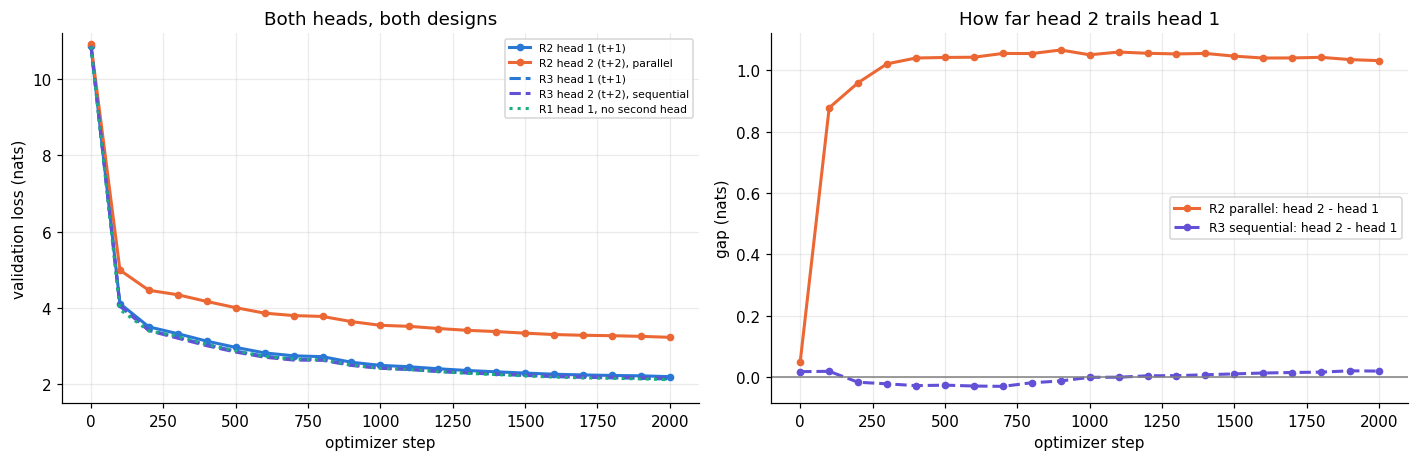

In [16]:
def val_series(res, key):
    "Validation curve of one head: (steps, losses)."
    return np.array([s for s, _ in res["val_hist"]]), np.array([e[key] for _, e in res["val_hist"]])

s2, L1_R2 = val_series(res_R2, "loss1"); _, L2_R2 = val_series(res_R2, "loss2")
s3, L1_R3 = val_series(res_R3, "loss1"); _, L2_R3 = val_series(res_R3, "loss2")
s1, L1_R1 = val_series(res_R1, "loss1")
print("validation loss during training:")
print(f"{'step':>6}{'R2 head 1':>11}{'R2 head 2':>11}{'R2 gap':>9}{'R3 head 1':>11}{'R3 head 2':>11}{'R3 gap':>9}{'R1 head 1':>11}")
for i, st in enumerate(s2):
    if st in (0, 100, 200, 300, 500, 1000, 1500, 2000) or i == len(s2) - 1:
        print(f"{st:>6}{L1_R2[i]:>11.4f}{L2_R2[i]:>11.4f}{L2_R2[i] - L1_R2[i]:>9.4f}"
              f"{L1_R3[i]:>11.4f}{L2_R3[i]:>11.4f}{L2_R3[i] - L1_R3[i]:>9.4f}{L1_R1[i]:>11.4f}")

print(f"\n{'run':<28}{'head 1':>9}{'head 2':>9}{'sum':>9}{'gap':>8}{'acc 1':>8}{'acc 2':>8}{'parameters':>13}")
for name, res, cname in [("R1 one head", res_R1, "tied, one head (R1)"),
                         ("R2 + parallel t+2 head", res_R2, "tied + parallel t+2 head (R2)"),
                         ("R3 + sequential t+2 head", res_R3, "tied + sequential t+2 head (R3)")]:
    fl = res["final"]
    if "loss2" in fl:
        print(f"{name:<28}{fl['loss1']:>9.4f}{fl['loss2']:>9.4f}{fl['loss1'] + fl['loss2']:>9.4f}"
              f"{fl['loss2'] - fl['loss1']:>8.4f}{fl['acc1']:>8.2%}{fl['acc2']:>8.2%}{counts6[cname]['total']:>13,}")
    else:
        print(f"{name:<28}{fl['loss1']:>9.4f}{'-':>9}{'-':>9}{'-':>8}{fl['acc1']:>8.2%}{'-':>8}{counts6[cname]['total']:>13,}")
print(f"\nhead 1 compared with R1: R2 {res_R2['final']['loss1'] - res_R1['final']['loss1']:+.4f}, "
      f"R3 {res_R3['final']['loss1'] - res_R1['final']['loss1']:+.4f} nats")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
ax = axes[0]
ax.plot(s2, L1_R2, "o-", color=C[0], ms=4, label="R2 head 1 (t+1)")
ax.plot(s2, L2_R2, "o-", color=C[1], ms=4, label="R2 head 2 (t+2), parallel")
ax.plot(s3, L1_R3, "--", color=C[0], label="R3 head 1 (t+1)")
ax.plot(s3, L2_R3, "--", color=C[6], label="R3 head 2 (t+2), sequential")
ax.plot(s1, L1_R1, ":", color=C[2], label="R1 head 1, no second head")
ax.set(xlabel="optimizer step", ylabel="validation loss (nats)", title="Both heads, both designs", ylim=(1.5, 11.2))
ax.legend(fontsize=7)
ax = axes[1]
ax.plot(s2, L2_R2 - L1_R2, "o-", color=C[1], ms=4, label="R2 parallel: head 2 - head 1")
ax.plot(s3, L2_R3 - L1_R3, "o--", color=C[6], ms=4, label="R3 sequential: head 2 - head 1")
ax.axhline(0, color="grey", lw=1)
ax.set(xlabel="optimizer step", ylabel="gap (nats)", title="How far head 2 trails head 1")
ax.legend(fontsize=8)
plt.tight_layout()
savefig("two_heads_val")
RESULTS["part2"] = {"R1_final": res_R1["final"], "R2_final": res_R2["final"], "R3_final": res_R3["final"]}
save_results()

### Part 2: what each head predicts, as strings

For each position of one validation story: the true next token and the true token after it, then each head's top
guess and the probability it gave the true answer. Expected: the parallel head 2 does well inside fixed phrases and
poorly right before a content word; the sequential head 2 does well almost everywhere head 1 does.

In [17]:
story = next(d for d in val_docs[2000:] if 40 <= len(d) <= 120)
st_tok = torch.from_numpy(story.astype(np.int64))[None].cuda()
with torch.no_grad(), torch.autocast("cuda", dtype=torch.bfloat16):
    h2 = model_R2(st_tok, doc=doc_ids(st_tok))
    p1 = model_R2.head(h2).float().softmax(-1)[0]                     # (L, V): row t predicts token t+1
    p2 = model_R2.head2(h2, st_tok).float().softmax(-1)[0]            # (L-2, V): row t predicts token t+2
    h3 = model_R3(st_tok, doc=doc_ids(st_tok))
    q2 = model_R3.head2(h3, st_tok).float().softmax(-1)[0]            # (L-2, V), reads the true token t+1
print(f"{'t':>3}  {'input':<12}| {'true t+1':<12}{'head 1 guess':<14}{'p':>6} | {'true t+2':<12}"
      f"{'R2 head 2':<14}{'p':>6} | {'R3 head 2':<14}{'p':>6}")
for t in range(min(26, len(story) - 2)):
    y1, y2 = int(story[t + 1]), int(story[t + 2])
    print(f"{t:>3}  {tok_str(story[t]):<12}| {tok_str(y1):<12}{tok_str(p1[t].argmax()):<14}{p1[t, y1].item():>6.2f} | "
          f"{tok_str(y2):<12}{tok_str(p2[t].argmax()):<14}{p2[t, y2].item():>6.2f} | "
          f"{tok_str(q2[t].argmax()):<14}{q2[t, y2].item():>6.2f}")

  t  input       | true t+1    head 1 guess       p | true t+2    R2 head 2          p | R3 head 2          p
  0  'Once'      | ' there'    ' upon'         0.11 | ' was'      ' a'            0.10 | ' was'          0.98
  1  ' there'    | ' was'      ' was'          0.97 | ' a'        ' a'            0.95 | ' a'            0.97
  2  ' was'      | ' a'        ' a'            0.96 | ' boy'      ' little'       0.10 | ' little'       0.10
  3  ' a'        | ' boy'      ' little'       0.10 | ' who'      ' girl'         0.09 | ' named'        0.24
  4  ' boy'      | ' who'      ' named'        0.24 | ' loved'    ' Jack'         0.03 | ' wanted'       0.19
  5  ' who'      | ' loved'    ' wanted'       0.16 | ' to'       ' to'           0.46 | ' to'           0.69
  6  ' loved'    | ' to'       ' to'           0.64 | ' play'     '.'             0.10 | ' play'         0.21
  7  ' to'       | ' play'     ' play'         0.25 | '.'         '.'             0.54 | ' with'         0.20
  8  ' pla

### Part 2: head 2 as a draft, and its acceptance rate

This is why MTP is used at inference. At each step head 1 emits the next token, and head 2 guesses the one after it
for free. The next forward pass checks the guess: if head 1 agrees, the guess is **accepted** and two tokens are
produced in one pass. With acceptance rate $a$, each forward pass yields $1 + a$ tokens on average (ignoring the
cost of checking). The sequential head reads head 1's own token at this point, exactly as it would at inference.

Caveat: the text here is a small model's greedy output, which repeats itself and makes guessing easier. Head 2's
accuracy on real validation text is printed next to it as the harder number.

In [18]:
prompts = torch.stack([torch.from_numpy(d[:32].astype(np.int64)) for d in val_docs[3000:] if len(d) > 40][:64]).cuda()
r_acc, seqs_by = {}, {}
for name, mm, res in [("R2 parallel head 2", model_R2, res_R2), ("R3 sequential head 2", model_R3, res_R3)]:
    a, seqs_by[name] = draft_acceptance(mm, prompts, 96)
    r_acc[name] = a
    print(f"{name}: drafts accepted {a:.1%} -> {1 + a:.2f} tokens per forward pass; "
          f"head-2 accuracy on real validation text {res['final']['acc2']:.1%} (head 1: {res['final']['acc1']:.1%})")
seqs = seqs_by["R2 parallel head 2"]
print("\nexample greedy continuation (R2), prompt | generated:")
print(enc.decode(seqs[0, :32].tolist()), "|", enc.decode([i for i in seqs[0, 32:].tolist() if i < 50257]))
RESULTS["part2"]["acceptance"] = r_acc
save_results()

R2 parallel head 2: drafts accepted 62.2% -> 1.62 tokens per forward pass; head-2 accuracy on real validation text 35.3% (head 1: 51.4%)
R3 sequential head 2: drafts accepted 83.4% -> 1.83 tokens per forward pass; head-2 accuracy on real validation text 51.9% (head 1: 52.2%)

example greedy continuation (R2), prompt | generated:
Once upon a time, there was a little boy called Tom. He loved the outdoors and he especially loved going to the big field near his home. He loved |  to explore the forest and look at the trees and the trees.

One day, Tom saw a big, shiny rock in the grass. He wanted to take it home, but he was scared. He tried to run away, but he couldn't. He was too scared to go back to the rock.

Tom's mom saw him and said, "Don't worry, Tom. I will help you. I will help you." Tom was happy and he ran


**Observations.**

**The two losses** (validation, after 2,000 steps):

| Run | Head 1 (t+1) | Head 2 (t+2) | Sum | Gap |
|---|---:|---:|---:|---:|
| R2, parallel head 2 | 2.1959 | **3.2270** | 5.4229 | **1.031** |
| R3, sequential head 2 | 2.1317 | 2.1511 | 4.2828 | 0.019 |
| R1, no second head | 2.1161 | | | |

**What happens to the parallel head 2 over training (R2):**
- Both heads start at 10.85-10.90 (sum 21.75 at step 1).
- **My prediction that they fall together for ~100 steps was wrong.** At the first evaluation, step 100, head 2 already
  trailed by 0.88 (4.99 vs 4.11).
- The gap reached 1.02 by step 300 and then **stayed flat** at 1.03-1.06 until the end (1.03). So it did not keep
  growing as I predicted. From step 300 on, both heads improved at the same pace, with head 2 about one nat behind.
  One nat means head 2 gives the right token about $e^1 \approx 2.7$ times less probability.
- The strings show where that nat goes:
  - head 2 is good inside fixed phrases: `' One'` → `' day'` (0.54), `' day'` → `','` (0.79);
  - it is helpless before content words: after `' his'` it must name the word after `' best'` without knowing
    `' best'`, and gives `' friend'` 0.00.
- Head 2's top-1 accuracy is 35.3%, against head 1's 51.4%.

**The sequential head 2 (R3):**
- It ended only **0.019** behind head 1. Between steps 200 and 1000 it was even slightly *ahead*, by up to about 0.03.
- It is told the next word, so it does nearly head 1's job one position later. In the strings table its column is
  head 1's column moved down one row. After `'Once'` it reads `' there'` and is 98% sure of `' was'`; the parallel
  head guessed `' a'`, as if the story began "Once upon a".
- It also has a transformer layer of its own. That plausibly explains why it was briefly ahead (not tested).

**The cost to head 1:**
- The parallel head made head 1 **0.080 worse** than R1 (2.196 vs 2.116); the sequential head cost only 0.016.
- The shared layers now serve a second goal, and at 30M parameters that costs quality.

**Drafting:**
- The parallel head's drafts were accepted **62.2%** of the time, 1.62 tokens per forward pass, a little above my
  predicted 35-60%. The sequential head's were accepted **83.4%** of the time, 1.83 tokens per pass.
- The greedy text repeats itself ("I will help you. I will help you."), which flatters both numbers.
- On real text, head 2's accuracy is 35.3% (parallel) and 51.9% (sequential).

## Part 3: broken harnesses that train beautifully

A target shift in the wrong direction can produce a beautiful loss curve. Bugs in the few lines between the model
output and the loss do not raise an exception. Five short runs (400 steps each, same starting weights, same data)
make that concrete:

| Run | The bug | What the model is really asked |
|---|---|---|
| **correct** | none | predict the next token |
| **no shift** | `cross_entropy(logits, tokens)` | "which token are you holding?": copy it |
| **reverse shift** | `cross_entropy(logits[:, 1:], tokens[:, :-1])` | "what was the previous token?": already visible |
| **no causal mask** | correct targets, but attention can look ahead | copy the next token, which it can now see |
| **pads counted** | one story per row, padded, pad targets scored | real targets, diluted by "pad follows pad" |

Each run logs the loss **its own harness reports**. Every 100 steps the model is also scored by the **correct**
harness on validation data: the honest number.

**Predictions.**
- **No shift, reverse shift, no causal mask:** the reported loss drops towards 0 within ~100 steps, because copying
  is far easier than language. The honest loss stays very bad, because what they learned is useless for the real
  task.
- **Pads counted:** about 60% of the targets are pads (stories of ~190 tokens in rows of 512), and those become free
  points. The reported loss should be about 40% of the real-token loss. The honest loss should be close to the
  correct run's.
- **The strings expose three of the four bugs, but not "no causal mask":** its input/target pairs are perfectly
  aligned. The bug is in the attention, not in the targets, and only the honest evaluation catches it.
- **Generations:** no shift repeats the last prompt word forever; reverse shift alternates the last two words; no
  causal mask produces nonsense, because at generation time there is no future token to copy.

In [19]:
pad_rows = torch.full((BUG_STEPS * B, T), PAD, dtype=torch.int32)        # one training story per row, right-padded
for i, d in enumerate(train_docs[:BUG_STEPS * B]):
    dd = d[:T]
    pad_rows[i, :len(dd)] = torch.from_numpy(dd)
pad_rows = pad_rows.cuda()
t_all = make_targets(pad_rows[:512].long(), 1, mask_pad=False, mask_boundary=False)
t_real = make_targets(pad_rows[:512].long(), 1)
f_pad = 1 - (t_real != IGNORE).sum().item() / t_all.numel()
print(f"share of targets that are padding in the padded rows: {f_pad:.1%}")

BUGS = [("correct", "none", None), ("no shift", "no_shift", None), ("reverse shift", "reverse_shift", None),
        ("no causal mask", "no_causal", None), ("pads counted", "count_pad", pad_rows)]
bug_res, bug_models = {}, {}
for name, bug, rows in BUGS:
    mm = build(Config())
    bug_res[name] = train(mm, steps=BUG_STEPS, data=train_tok, rows=rows, val=val_windows, bug=bug, warmup=50,
                          label=f"bug: {name}", log_every=100)
    bug_models[name] = mm
RESULTS["part3"] = {k: {kk: v[kk] for kk in ("hist", "val_hist", "final")} for k, v in bug_res.items()}
save_results()

share of targets that are padding in the padded rows: 61.7%
  [bug: correct] 400 steps x 8,192 tokens; val loss before training: head 1 10.8539
  [bug: correct] step     1/400  train loss1 10.8545  grad norm 10.876  lr 2.00e-05
  [bug: correct] step   100/400  train loss1 3.8921  grad norm 0.666  lr 9.57e-04  | val head 1 3.8663
  [bug: correct] step   200/400  train loss1 3.5703  grad norm 0.725  lr 6.52e-04  | val head 1 3.3894
  [bug: correct] step   300/400  train loss1 2.9151  grad norm 0.724  lr 2.70e-04  | val head 1 3.1849
  [bug: correct] step   400/400  train loss1 2.5519  grad norm 0.583  lr 1.00e-04  | val head 1 3.0090
  [bug: no shift] 400 steps x 8,192 tokens; val loss before training: head 1 10.8539
  [bug: no shift] step     1/400  train loss1 8.9468  grad norm 21.681  lr 2.00e-05
  [bug: no shift] step   100/400  train loss1 0.0667  grad norm 0.149  lr 9.57e-04  | val head 1 14.9514
  [bug: no shift] step   200/400  train loss1 0.0262  grad norm 0.080  lr 6.52e-04  | 

The input -> target pairs each harness builds, as strings:
  correct         'One'->' day'  ' day'->','  ','->' a'  ' a'->' little'  ' little'->' girl'    [aligned correctly]
  no shift        'One'->'One'  ' day'->' day'  ','->','  ' a'->' a'  ' little'->' little'    [target = the input itself]
  reverse shift   ' day'->'One'  ','->' day'  ' a'->','  ' little'->' a'  ' girl'->' little'    [target = the previous input]
  no causal mask  'One'->' day'  ' day'->','  ','->' a'  ' a'->' little'  ' little'->' girl'    [aligned correctly: the bug is in the attention mask, invisible here]
  pads counted    ' together'->'.'  '.'-><eot>  <eot>-><pad>  <pad>-><pad>  <pad>-><pad>    [end of a row: <eot> -> <pad>, <pad> -> <pad> are scored]

run              reported, step 1  reported, end  real-token loss  honest val loss
correct                   10.8545         2.8474              nan           3.0090
no shift                   8.9468         0.0128              nan          18.6332
reverse shi

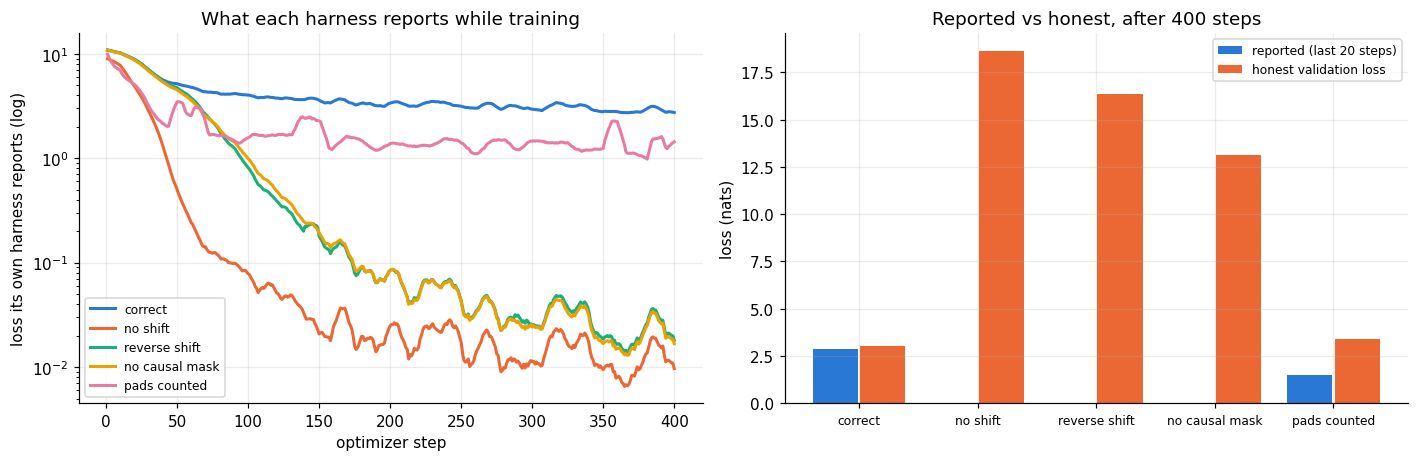

In [20]:
row = train_tok[:T].long()
print("The input -> target pairs each harness builds, as strings:")
for name, bug, _ in BUGS:
    if bug == "count_pad":
        r = pad_rows[0].long()
        L0 = int((r != PAD).sum())
        pairs, note = [(r[p], r[p + 1]) for p in range(L0 - 3, L0 + 2)], "end of a row: <eot> -> <pad>, <pad> -> <pad> are scored"
    elif bug == "no_shift":
        pairs, note = [(row[p], row[p]) for p in range(5)], "target = the input itself"
    elif bug == "reverse_shift":
        pairs, note = [(row[p], row[p - 1]) for p in range(1, 6)], "target = the previous input"
    else:
        pairs = [(row[p], row[p + 1]) for p in range(5)]
        note = "aligned correctly" + (": the bug is in the attention mask, invisible here" if bug == "no_causal" else "")
    print(f"  {name:<15} " + "  ".join(f"{tok_str(a)}->{tok_str(b)}" for a, b in pairs) + f"    [{note}]")

print(f"\n{'run':<16}{'reported, step 1':>17}{'reported, end':>15}{'real-token loss':>17}{'honest val loss':>17}")
for name, _, _ in BUGS:
    r = bug_res[name]
    rep = np.mean([h[1] for h in r["hist"][-20:]])
    real = np.mean([h[3] for h in r["hist"][-20:]]) if name == "pads counted" else float("nan")
    print(f"{name:<16}{r['hist'][0][1]:>17.4f}{rep:>15.4f}{real:>17.4f}{r['final']['loss1']:>17.4f}")

prompt = torch.tensor([enc.encode_ordinary("Once upon a time, there was a little")], device="cuda")
print("\nGreedy continuation of 'Once upon a time, there was a little':")
for name, bug, _ in BUGS:
    out = generate(bug_models[name], prompt, 16, causal=(bug != "no_causal"))
    print(f"  {name:<15} |{enc.decode([i for i in out[0, prompt.shape[1]:].tolist() if i < 50257])!r}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
for i, (name, _, _) in enumerate(BUGS):
    r = bug_res[name]
    axes[0].plot([h[0] for h in r["hist"]], smooth([h[1] for h in r["hist"]], 10), color=C[i], label=name)
axes[0].set(yscale="log", xlabel="optimizer step", ylabel="loss its own harness reports (log)",
            title="What each harness reports while training")
axes[0].legend(fontsize=8)
names = [n for n, _, _ in BUGS]
x = np.arange(len(names))
axes[1].bar(x - 0.2, [np.mean([h[1] for h in bug_res[n]["hist"][-20:]]) for n in names], 0.38, color=C[0],
            label="reported (last 20 steps)")
axes[1].bar(x + 0.2, [bug_res[n]["final"]["loss1"] for n in names], 0.38, color=C[1], label="honest validation loss")
axes[1].set_xticks(x, names, fontsize=8)
axes[1].set(ylabel="loss (nats)", title="Reported vs honest, after 400 steps")
axes[1].legend(fontsize=8)
plt.tight_layout()
savefig("bug_zoo")

**Observations.**
- **All three copy bugs produced beautiful curves.** After 400 steps they report:
  - 0.013 (no shift);
  - 0.024 (reverse shift);
  - 0.022 (no causal mask).

  The correct harness reports 2.85. Judged by the reported loss alone, each bug looks over 100× better.
- **Their honest losses are disastrous: 18.6, 16.4 and 13.1**, far worse than a uniform guess (10.83). The models are
  confidently wrong, and they got *worse* the longer they trained (no shift: 14.95 at step 100 → 18.63 at step 400).
- **No shift learned fastest** (0.07 by step 100): copying the token a position already holds needs no attention at
  all. Reverse shift and no causal mask need one attention step to fetch a neighbour, and their curves fall almost
  on top of each other.
- **No shift started lower even at step 1** (8.95 vs 10.85). With a tied head, an untrained model already gives the
  token it is reading a higher score (the same effect as the pad targets in Task 3).
- **Pads counted:**
  - 61.7% of its targets were padding;
  - it reported 1.50 while its loss on the real targets of the same batches was 3.42, so the reported number was
    44% of the real one (predicted ~38%: the pad targets became cheap, not free);
  - its honest loss, 3.37, is 0.36 worse than the correct run's 3.01, because it saw only 38% as many real tokens.
- **The strings caught three of the four bugs**, as predicted: `'One'->'One'`, `' day'->'One'` and `<pad>-><pad>`
  are visible at a glance. "No causal mask" prints perfectly aligned pairs; only the honest evaluation exposes it.
- **Generations:**
  - no shift repeats `' little'` forever, and reverse shift alternates `' a little a little'`, as predicted;
  - **my prediction for no causal mask was wrong:** instead of nonsense, it also repeats `' little'`. With no future
    token to copy, it apparently falls back to the token it is reading;
  - the pads-counted model writes a normal story, because apart from the padding it learned real language.

## Summary of every headline number

In [21]:
R = RESULTS
print("PART 1")
print(f" 1. shapes: logits {tuple(R['task1']['logits_shape'])} = {R['task1']['logits_mib']:.1f} MiB vs hidden "
      f"{R['task1']['hidden_mib']:.1f} MiB; {R['task1']['ratio_elements']:.1f}x as many numbers")
print(f" 2. shift: {R['task2']['aligned']:,} / {R['task2']['scored']:,} scored targets equal the next input; "
      f"{R['task2']['unscored']} unscored = {R['task2']['eot_inputs']} <eot> inputs")
for k in ("untrained", "trained R1"):
    r = R["task3"][k]
    print(f" 3. padding ({k}): contributing targets {r['n_all']} -> {r['n_real']}; loss counted {r['counted']:.4f} -> "
          f"masked {r['masked']:.4f}")
for k in ("untrained", "trained R1"):
    r = R["task4"][k]
    print(f" 4. packing ({k}): {r['loss_a']:.4f} (n = {r['n_a']}) -> boundary masked {r['loss_b']:.4f} (n = {r['n_b']}) "
          f"-> + document-aware attention {r['loss_c']:.4f}")
for k, v in R["task5"]["measured"].items():
    print(f" 5. untrained perplexity, {k}: {math.exp(v):,.0f} = {math.exp(v) / V:.3f} x V")
c6 = R["task6"]["counts"]
print(f" 6. parameters: tied {c6['tied, one head (R1)']['total']:,} vs untied {c6['untied, one head']['total']:,}")
t7 = R["task7"]
print(f" 7. peak memory of the loss at {t7['N']:,} positions: ordinary {t7['ordinary']['peak_mib'] / 1024:.2f} GiB vs "
      f"chunked {t7['chunked_1024']['peak_mib'] / 1024:.2f} GiB -> {t7['ratio']:.1f}x")
print("PART 2 (validation)")
for k, lab in (("R2_final", "parallel head 2"), ("R3_final", "sequential head 2")):
    f = R["part2"][k]
    print(f"   {lab}: head 1 {f['loss1']:.4f}, head 2 {f['loss2']:.4f}, sum {f['loss1'] + f['loss2']:.4f}")
print(f"   R1 head 1 alone: {R['part2']['R1_final']['loss1']:.4f};  drafts accepted: " +
      ", ".join(f"{k} {v:.1%}" for k, v in R["part2"]["acceptance"].items()))
print("PART 3 (reported at the end -> honest validation)")
for k, v in R["part3"].items():
    print(f"   {k:<15} {np.mean([h[1] for h in v['hist'][-20:]]):.4f} -> {v['final']['loss1']:.4f}")
print(f"\nwhole notebook: {(time.time() - T_START) / 60:.1f} min")
save_results()

PART 1
 1. shapes: logits (16, 512, 50304) = 786.0 MiB vs hidden 12.0 MiB; 131.0x as many numbers
 2. shift: 8,129 / 8,129 scored targets equal the next input; 47 unscored = 47 <eot> inputs
 3. padding (untrained): contributing targets 764 -> 485; loss counted 10.3318 -> masked 10.8289
 3. padding (trained R1): contributing targets 764 -> 485; loss counted 5.5366 -> masked 1.6241
 4. packing (untrained): 10.8676 (n = 132) -> boundary masked 10.8689 (n = 131) -> + document-aware attention 10.8525
 4. packing (trained R1): 2.4168 (n = 132) -> boundary masked 2.3260 (n = 131) -> + document-aware attention 2.0567
 5. untrained perplexity, tied (R1 at step 0): 52,060 = 1.035 x V
 5. untrained perplexity, untied: 53,514 = 1.064 x V
 6. parameters: tied 29,938,560 vs untied 49,255,296
 7. peak memory of the loss at 8,176 positions: ordinary 3.87 GiB vs chunked 0.43 GiB -> 9.1x
PART 2 (validation)
   parallel head 2: head 1 2.1959, head 2 3.2270, sum 5.4229
   sequential head 2: head 1 2.1317,

## Limits of this work

- **One seed, one small model.** A 30M model on 16.4M TinyStories tokens. Differences of a few hundredths of a nat
  (for example, how much head 2 costs head 1) are within what a different seed could move. MTP's reported benefits
  appear at billions of parameters, which is not tested here.
- **R1 was trained with the fixed harness.** It never saw a `<pad>`, never predicted across an `<eot>` and never
  looked across stories. So the trained numbers in Tasks 3 and 4 show how a correctly trained model reacts to the
  broken harness, not how a model trained on the broken harness would behave. Part 3 trains such models, but only
  for 400 steps.
- **Peak memory** is `max_memory_allocated`: the bytes held by tensors. It leaves out the allocator's cached blocks
  and the CUDA context. The out-of-memory points are those of one L4.
- **The chunked loss is plain PyTorch, not a fused GPU kernel.** It saves memory but still writes each chunk's
  scores to GPU memory and loops in Python, so its timings show the cost of this implementation only.
- **Draft acceptance** is measured on a small model's greedy text, which repeats itself.
- **Single-seed details in Part 2.** Three results are one run each and their explanations were not tested: the head-1
  cost of each design (0.080 vs 0.016), the sequential head 2 being briefly ahead of head 1, and its extra layer as
  the reason. Testing would mean, for example, giving the parallel head the same extra layer.
- **The untrained perplexity ratio** (1.035 tied, 1.064 untied, against my 1.08 estimate) depends on one random
  initialisation.
- **The "no causal mask" generation** (it repeats the last word) is one prompt, and its explanation is a guess.

## Disconnect the runtime

This cell releases the Colab GPU so it stops using compute units. **After it runs, press Ctrl+S in VS Code** so the
outputs are saved into the notebook file.

In [22]:
save_results()
print("results.json and plots/ are written; releasing the Colab runtime now.")
try:
    from google.colab import runtime
    runtime.unassign()
except Exception as e:                                       # not on Colab, or already released
    print(f"runtime.unassign() not available here ({type(e).__name__}); disconnect the runtime manually")

results.json and plots/ are written; releasing the Colab runtime now.
